<a href="https://colab.research.google.com/github/mariobet23440/Proyecto-3---M-todos-Num-ricos-1/blob/main/Proyecto3MetodosNumericos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ***MOTOR DC - GEMELO DIGITAL Y CONTROL PID***

```Proyecto 3 - Métodos Numéricos 1```

***Creado por:***
*   Mario Betancourt (23440)
*   Pongan sus nombres y (carnets)

## ***HISTORIAL DE REVISIONES***
*   21/11/2026 - Creación de archivo y método de Euler
*   22/11/2026 - Correcciones al desarrollo matemático de la Parte 1, revisadas y aprobadas por el equipo (ver `UsoIA/`)
*   22/11/2026 - Referencia a Nise (7.ª ed.) en la Introducción y sección de Referencias
*   22/11/2026 - Sección 1.4 completada (papel del Jacobiano en la estabilidad, regularización con tanh) y nueva sección 1.5 (espacios métricos y condición de Lipschitz), redactadas con IA
*   22/11/2026 - Animaciones de Euler, estabilidad y Lipschitz (generadas con IA)
*   22/11/2026 - Funciones de derivación numérica (adaptadas del cuaderno de Grettel y Deyler y documentadas con IA)
*   22/11/2026 - Se acopló la aplicación de la derivación a las mediciones (secciones 2.4 a 2.6) y se agregó la Parte 3, Integración numérica (adaptada del cuaderno de Grettel y Deyler )
*   22/11/2026 - Corrección de numeración (2.2.4 → 2.3.4) y se completó la discusión de Richardson con paso irregular; se reemplazó la celda inconclusa "Por sí solo, un encoder de cuadratura permite..."



# ***INTRODUCCIÓN***
Le damos la bienvenida al cuaderno de Jupyter del Proyecto 3 del curso Métodos Numéricos 1 de la Universidad del Valle de Guatemala. En este proyecto trabajaremos en la aplicación de métodos numéricos para calcular derivadas e integrales y métodos de resolución de ecuaciones diferenciales al análisis de la dinámica de un motor DC.

De acuerdo con la guía, el motor DC se modela a través de un sistema de tres ecuaciones diferenciales acopladas:

$$\begin{cases}
L\frac{di}{dt} = V-Ri-K_e \omega \\
J_m\frac{d\omega}{dt} = K_t i - b\omega -\tau_c \text{ sign}(\omega) - \tau_{carga} \\
\frac{d\theta}{dt} = \omega
\end{cases}$$

Donde los símbolos representan las siguientes cantidades físicas

*   $L$ - Inductancia del motor [henrios, H]
*   $V$ - Voltaje aplicado en las terminales del motor [Volts, V]
*   $R$ - Resistencia del motor [Ohms, $\Omega$]
*   $K_e$ - Constante de fuerza contraelectromotriz [$V/(rad/s)$]
*   $\omega$ - Velocidad angular del motor [radianes por segundo, $rad/s$]
*   $J_m$ - Inercia del eje del motor [$\text{kg}\cdot\text{m}^2$]
*   $K_t$ - Constante de torque del motor [$\text{N}\cdot\text{m}/\text{A}$]
*   $b$ - Coeficiente de amortiguamiento viscoso [$\text{N}\cdot\text{m}\cdot\text{s}/\text{rad}$]
*   $\tau_c$ - Torque de fricción de Coulomb [$\text{N}\cdot\text{m}$]
*   $\tau_{carga}$ - Torque de carga [$\text{N}\cdot\text{m}$]

Un estudio de estos modelos en cursos de sistemas de control sugiere que el sistema de ecuaciones representa a un motor DC controlado por armadura. Este modelo de motores DC supone que la corriente en el estator (corriente de campo) es constante y el control de movimiento se realiza por la corriente del devanado del rotor (devanado de armadura). Este modelo de motores es aplicable también a motores DC de imanes permanentes. El motor DC JGA25-370 entra dentro de esta categoría. Para más información sobre este modelo en su versión lineal, véase Nise [1, cap. 2, §2.8, pp. 77–83].


A diferencia del modelo lineal presentado en Nise [1, §2.8], el modelo analizado en este proyecto agrega una dificultad adicional: *se considera un término no lineal para la fricción de Coulomb*. Aunque es posible linealizar el sistema y analizarlo a través de Transformadas de Laplace (como se hace en Sistemas de Control 1), ese no es el objetivo de este proyecto. Al fin y al cabo, el objetivo de este curso no es simplificar el modelo, sino resolverlo numéricamente tal cual. Por lo tanto, a diferencia de lo que se haría en un análisis de sistemas lineales, en este proyecto resolveremos la ecuación original con todas sus no linealidades.

# ***OBJETIVOS***

**General.** Construir un gemelo digital de un motor DC con encoder (JGA25-370) a partir de mediciones reales, y usarlo para diseñar un controlador PID que se implementa en un Arduino.

**Específicos.**
1. Modelar el motor como un sistema de EDO eléctrico-mecánico acoplado, con fricción viscosa y de Coulomb, y estimar sus parámetros con las mediciones.
2. Implementar y comparar Euler, Heun, RK2 y RK4: precisión, orden de convergencia, estabilidad y costo, y relacionar el paso máximo de Euler con la constante de tiempo eléctrica $L/R$.
3. Obtener la velocidad a partir de la posición cuantizada del encoder con diferencias finitas, Richardson y conteo en ventana, y analizar el compromiso entre ruido y retraso.
4. Calcular energías con el trapecio, Simpson y Gauss-Legendre, y cerrar el balance de energía de cada prueba.
5. Diseñar, sintonizar e implementar un controlador PID de velocidad y de posición, y comparar la respuesta real con la simulada.

# ***PARTE 1 - SOLUCIÓN DE SISTEMAS DE ECUACIONES DIFERENCIALES***

Ahora que fijamos como objetivo resolver el sistema de ecuaciones diferenciales mostrado anteriormente, surge la importante pregunta de cómo debemos proceder. Empecemos tratando de entender cómo resolver un sistema de ecuaciones a través del método de Euler.

## **1.1. El Método de Euler para una EDO de primer orden**
El método de Euler es fácil y muy intuitivo de definir para un Problema de Valores Iniciales (PVI) con una EDO de primer orden:

$$\begin{cases}
\frac{dy}{dx}=f(x,y)\\
y(x_0) = y_0
\end{cases}
$$

Donde $x_0$ y $y_0$ son constantes arbitrarias. Para aproximar la solución a este PVI, utilizamos diferencias finitas hacia adelante para aproximar la derivada en $x_k$ usando el intervalo $[x_k, x_{k+1}]$, donde $x_{k+1} = x_k + h$:

$$\frac{dy}{dx} \approx \frac{y_{k+1} - y_k}{h} $$

Donde $y_{k+1} \approx y(x_{k+1})$ y $y_{k} \approx y(x_{k})$ son las **aproximaciones numéricas** de la variable dependiente en los extremos del intervalo antes definido. (En la sección 1.4 se usará una letra mayúscula para distinguir la solución exacta).

Al sustituir en la EDO, evaluando $f$ en el extremo izquierdo del intervalo, $(x_k, y_k)$:
$$\frac{y_{k+1} - y_k}{h}\approx f(x_k,y_k)$$

Evaluar $f$ en el extremo izquierdo es justamente lo que hace que el método sea **explícito**; evaluarla en $(x_{k+1}, y_{k+1})$ daría el método de Euler implícito.

Resuelva para $y_{k+1}$ y obtendrá la ecuación del método de Euler explícito (el método de Euler que aproxima la solución extrapolando hacia adelante usando la derivada en el punto actual):

$$y_{k+1} = y_k + hf(x_k, y_k)$$

¿Ve lo simple que es llegar a este famoso método?



![Método de Euler paso a paso](https://raw.githubusercontent.com/mariobet23440/Proyecto-3---M-todos-Num-ricos-1/main/Animaciones/euler_paso_a_paso.gif)

**Animación: el método de Euler paso a paso.** Se aplica a la ecuación eléctrica del motor con el rotor detenido, $L\,\frac{di}{dt} = V - R\,i$, cuya solución exacta es $i(t) = \frac{V}{R}\left(1 - e^{-t/\tau}\right)$ con $\tau = L/R$. En cada paso se traza la tangente con la pendiente $f(t_k, i_k)$ y se avanza una distancia $h$. Las líneas punteadas naranjas muestran el error acumulado respecto de la solución exacta.

*Animación generada por Claude Opus 5.5 (Anthropic), asistente de IA, a pedido de los autores. Código: `Animaciones/generar_animaciones.py`.*

## **1.2. El Método de Euler para un sistema de EDOs de primer orden**
Ahora extrapolemos esta deducción hacia un sistema de varias EDOs de variables dependientes en el vector $\mathbf{y}=[y_1, y_2, ..., y_N]^T$. ¿Qué tanto podría cambiar?

Suponga que todas las ecuaciones del sistema pueden escribirse en forma canónica (aunque el lado derecho sea una no linealidad espeluznante):

$$
\begin{cases}
y_1' = f_1(x,y_1,y_2, ..., y_N)\\
y_2' = f_2(x,y_1,y_2, ..., y_N)\\
y_3' = f_3(x,y_1,y_2, ..., y_N)\\
\vdots \\
y_N' = f_N(x,y_1,y_2, ..., y_N)
\end{cases}
$$

Aunque no lo crea, este sistema de ecuaciones grita que puede ser expresado en forma vectorial. Reúna las variables dependientes en el vector $\mathbf{y}$ y los lados derechos en una sola función vectorial $\mathbf{f}$, el **campo vectorial** del sistema:

$$
\mathbf{y} = \begin{pmatrix} y_1 \\ y_2 \\ \vdots \\ y_N \end{pmatrix},\qquad
\mathbf{f}(x,\mathbf{y}) = \begin{pmatrix} f_1(x,\mathbf{y}) \\ f_2(x,\mathbf{y}) \\ \vdots \\ f_N(x,\mathbf{y}) \end{pmatrix}
$$

Si recuerda que derivar una función vectorial equivale a derivar cada una de sus componentes, $\mathbf{y}' = [y_1', y_2', ..., y_N']^T$, todo el sistema cabe en una sola línea:

$$\mathbf{y}' = \mathbf{f}(x,\mathbf{y})$$

¡Para sistemas de EDOs de primer orden, la función de pendiente escalar $f(x,y)$ se reemplaza por un campo vectorial $\mathbf{f}(x,\mathbf{y})$!

Resolver el sistema de ecuaciones mediante el método de Euler es realmente sencillo: aproxime la derivada de cada variable dependiente en el sistema a través de diferencias finitas y resuelva para el valor de la función en el extremo derecho del intervalo sobre el que se aproxima. Básicamente, haga lo mismo que hicimos antes para deducir que $y_{k+1} = y_k + hf(x_k, y_k)$ pero *por cada función $y_i$ en el sistema de EDOs*.

De esta forma, por cada iteración $k$, $x_k = x_0 + hk$ y por cada variable dependiente:

$$
\begin{aligned}
(y_1)_{k+1} &= (y_1)_{k} + h f_1 (x_k, (y_1)_k, (y_2)_k, ..., (y_N)_k)\\
(y_2)_{k+1} &= (y_2)_{k} + h f_2 (x_k, (y_1)_k, (y_2)_k, ..., (y_N)_k)\\
&\ \ \vdots\\
(y_N)_{k+1} &= (y_N)_{k} + h f_N (x_k, (y_1)_k, (y_2)_k, ..., (y_N)_k)
\end{aligned}
$$

Estas $N$ fórmulas son exactamente las componentes de una sola ecuación vectorial. Por lo tanto, para un sistema de ecuaciones la fórmula iterativa del método de Euler puede reescribirse en forma vectorial:

$$\mathbf{y}_{k+1} =\mathbf{y}_{k} + h\,\mathbf{f}(x_k, \mathbf{y}_{k})$$

Esta forma de expresar la fórmula iterativa del método de Euler es extremadamente importante. Por favor, recuérdela, que será de mucha utilidad cuando tratemos de estudiar la estabilidad del método en este caso.

## **1.3. Sistemas de EDOs de orden superior**
Ahora considere que agregamos la complejidad adicional de que en nuestro sistema de ecuaciones: tenemos al menos una ecuación con una derivada de orden superior de una variable dependiente. La solución, en este caso, es bastante simple: *reemplace la derivada de orden superior por una derivada de primer orden utilizando variables auxiliares*.

Para ilustrar mejor esta idea, olvide que tratamos con sistemas de ecuaciones y considere lo que ocurre con una sola EDO de segundo orden:

$$\frac{d^2y}{dt^2} = \frac{dy}{dt} - 1$$

En este caso, podemos convertir la ecuación de segundo orden en un *sistema* de ecuaciones de primer orden sustituyendo la derivada de segundo orden por la derivada de una variable auxiliar. Considere que $u_1 = y$ y $u_2 = y'$. Para este problema se obtiene el sistema de EDOs de primer orden:

$$\begin{cases}
\frac{du_2}{dt}= u_2 - 1\\
\frac{du_1}{dt}= u_2
\end{cases}
$$

Por lo tanto, en un sistema de ecuaciones donde aparecen múltiples EDOs de orden superior, cada EDO de orden $n$ se descompone en exactamente $n$ EDOs de primer orden, usando las variables auxiliares $u_1 = y,\ u_2 = y',\ \dots,\ u_n = y^{(n-1)}$. En este ejemplo, dado que la ecuación era de segundo orden (orden 2), se necesitaron 2 ecuaciones de primer orden.

Observe que el modelo del motor ya está escrito como un sistema de primer orden, con vector de estado $\mathbf{y} = [i,\ \omega,\ \theta]^T$: la ecuación $\frac{d\theta}{dt} = \omega$ es justamente la reducción de orden de la ecuación de segundo orden para $\theta$.

Con esto mencionado, ya tenemos la teoría suficiente para (1) aplicar el método de Euler y generalizar a otros métodos para resolver EDOs vistos en el curso y (2) Analizar la estabilidad de la solución numérica, al menos para el método de Euler.

## **1.3. Otros métodos: Heun, RK2 y RK4**

Euler usa solo la pendiente al inicio del paso. Los métodos de Runge-Kutta usan varias pendientes dentro del mismo paso y las combinan, con la misma notación de la sección 1.2: el estado es $\mathbf{y}_k$, el paso es $h$ y $\mathbf{f}(x, \mathbf{y})$ es el campo vectorial del sistema.

**Heun (Euler mejorado).** Primero se predice con Euler y luego se corrige promediando la pendiente del inicio y la del final del paso:

$$\mathbf{k}_1 = \mathbf{f}(x_k, \mathbf{y}_k), \qquad \mathbf{k}_2 = \mathbf{f}(x_k + h,\ \mathbf{y}_k + h\,\mathbf{k}_1), \qquad \mathbf{y}_{k+1} = \mathbf{y}_k + \frac{h}{2}\left(\mathbf{k}_1 + \mathbf{k}_2\right)$$

**RK2 (punto medio).** Se usa la pendiente evaluada a la mitad del paso:

$$\mathbf{k}_1 = \mathbf{f}(x_k, \mathbf{y}_k), \qquad \mathbf{k}_2 = \mathbf{f}\!\left(x_k + \tfrac{h}{2},\ \mathbf{y}_k + \tfrac{h}{2}\,\mathbf{k}_1\right), \qquad \mathbf{y}_{k+1} = \mathbf{y}_k + h\,\mathbf{k}_2$$

Heun y el punto medio son métodos de segundo orden: el error global es proporcional a $h^2$.

**RK4 (Runge-Kutta clásico).** Usa cuatro pendientes: una al inicio, dos a la mitad del paso y una al final, y las pondera como en la regla de Simpson:

$$\mathbf{k}_1 = \mathbf{f}(x_k, \mathbf{y}_k), \qquad \mathbf{k}_2 = \mathbf{f}\!\left(x_k + \tfrac{h}{2},\ \mathbf{y}_k + \tfrac{h}{2}\mathbf{k}_1\right), \qquad \mathbf{k}_3 = \mathbf{f}\!\left(x_k + \tfrac{h}{2},\ \mathbf{y}_k + \tfrac{h}{2}\mathbf{k}_2\right), \qquad \mathbf{k}_4 = \mathbf{f}(x_k + h,\ \mathbf{y}_k + h\,\mathbf{k}_3)$$

$$\mathbf{y}_{k+1} = \mathbf{y}_k + \frac{h}{6}\left(\mathbf{k}_1 + 2\mathbf{k}_2 + 2\mathbf{k}_3 + \mathbf{k}_4\right)$$

RK4 es de cuarto orden (error global $\propto h^4$) y cuesta cuatro evaluaciones de $\mathbf{f}$ por paso, contra una de Euler y dos de Heun o RK2. En el motor, $x$ es el tiempo $t$ y $\mathbf{y} = [i,\ \omega,\ \theta]^T$. Las implementaciones están en la Parte 4 (`paso_euler`, `paso_heun`, `paso_rk2` y `paso_rk4`).

## **1.4. Estabilidad Numérica del Método de Euler**
Suponga que la solución exacta del sistema de EDOs en $x_k$ es $\mathbf{Y}(x_k)$ (observe que se usó una letra mayúscula). Esta puede calcularse de forma exacta en las cercanías de $x_k$ al utilizar series de Taylor y agregar un término de error local $\mathbf{T}_k$ por los términos de orden superior:

$$\mathbf{Y}(x_{k+1}) = \mathbf{Y}(x_k) + h\,\mathbf{f}(x_k, \mathbf{Y}(x_k)) + \mathbf{T}_k$$

Como $\mathbf{Y}$ es una función vectorial, el residuo de Taylor se escribe componente a componente: cada componente tiene su propio punto intermedio $\epsilon_i \in (x_k, x_{k+1})$,

$$(\mathbf{T}_k)_i = \frac{h^2}{2}\,Y_i''(\epsilon_i), \qquad i = 1, 2, \dots, N$$

En general no existe un único $\epsilon$ que sirva para todas las componentes a la vez. Lo que sí se puede afirmar es la cota

$$\|\mathbf{T}_k\| \le \frac{h^2}{2}\max_{x\in[x_k,x_{k+1}]}\|\mathbf{Y}''(x)\|$$

Definimos el error en el paso $k$ como $\mathbf{e}_{k} = \mathbf{Y}(x_{k}) - \mathbf{y}_{k}$. Al restar la fórmula de Euler $\mathbf{y}_{k+1} = \mathbf{y}_k + h\,\mathbf{f}(x_k, \mathbf{y}_k)$ de la expansión de Taylor, el error en el paso $k+1$ es:

$$\mathbf{e}_{k+1} = \mathbf{Y}(x_{k+1}) - \mathbf{y}_{k+1} = [\mathbf{Y}(x_k)-\mathbf{y}_{k}] + h[\mathbf{f}(x_k, \mathbf{Y}(x_k)) - \mathbf{f}(x_k, \mathbf{y}_k)] + \mathbf{T}_k$$

Este error tiene tres componentes:
- $[\mathbf{Y}(x_k) - \mathbf{y}_k] = \mathbf{e}_k$ es el error global acumulado hasta el paso $k$.
- $h[\mathbf{f}(x_k, \mathbf{Y}(x_k)) - \mathbf{f}(x_k, \mathbf{y}_k)]$ es el error propagado por la pendiente: muestra cómo el error en el paso anterior influye en el error de la pendiente del paso siguiente.
- $\mathbf{T}_k$ es el error de truncamiento local, se agrega por la Serie de Taylor.

Un método de resolución de sistemas de EDOs es **numéricamente estable** si, conforme $k$ aumenta, los errores que ya existen no crecen sin control: la solución numérica no "explota" (en pocas palabras). No hay que confundir esto con la **convergencia**, que pide que la solución numérica se acerque a la analítica cuando $h \to 0$. Las dos ideas se relacionan: un método *consistente* (cuyo error local cumple $\mathbf{T}_k/h \to \mathbf{0}$) y estable es convergente.

Para ser completamente honestos con usted, en esta parte no supimos cómo proceder. La mayoría de videos en internet que hablan respecto al tema utilizan el Jacobiano bajo el supuesto de que los sistemas de EDOs que se resuelven son lineales. Al consultar con Claude AI (2026) sobre cómo se debería proceder con el análisis que estamos haciendo, esta sugirió que la ****

La definición de $\mathbf{e}_{k+1}$ sugiere que el error en el paso $k+1$ depende del error en el paso $k$ a través de la pendiente. Para saber si ese error crece o se atenúa hay que responder una pregunta: **¿cuánto cambia $\mathbf{f}$ cuando su argumento pasa de $\mathbf{y}_k$ a $\mathbf{Y}(x_k)$?** Esa es justamente la pregunta que responde la derivada de $\mathbf{f}$.

### **El Jacobiano: la derivada del campo vectorial**

Observe la diferencia de papeles. El método de Euler se calcula siempre con el campo vectorial $\mathbf{f}$, sea el sistema lineal o no. El Jacobiano, que es la derivada de $\mathbf{f}$, no forma parte del método: aparece solo al analizar cómo se propaga el error.

Recuerde cómo se define. Sea $\mathbf{f}: \mathbb{R}^n \to \mathbb{R}^m$ una función vectorial diferenciable definida por $\mathbf{f}(\mathbf{x}) = (f_1(\mathbf{x}), f_2(\mathbf{x}), \dots, f_m(\mathbf{x}))$, donde $\mathbf{x} = (x_1, x_2, \dots, x_n)$. La *matriz jacobiana* de $\mathbf{f}$ en $\mathbf{x}$, denotada por $\mathbf{J}_{\mathbf{f}}(\mathbf{x})$ o $\frac{\partial \mathbf{f}}{\partial \mathbf{x}}$, es la matriz de $m \times n$ de sus primeras derivadas parciales:

$$
\mathbf{J}_{\mathbf{f}}(\mathbf{x}) = \frac{\partial (f_1, \dots, f_m)}{\partial (x_1, \dots, x_n)} =
\begin{pmatrix}
\frac{\partial f_1}{\partial x_1} & \frac{\partial f_1}{\partial x_2} & \cdots & \frac{\partial f_1}{\partial x_n} \\
\frac{\partial f_2}{\partial x_1} & \frac{\partial f_2}{\partial x_2} & \cdots & \frac{\partial f_2}{\partial x_n} \\
\vdots & \vdots & \ddots & \vdots \\
\frac{\partial f_m}{\partial x_1} & \frac{\partial f_m}{\partial x_2} & \cdots & \frac{\partial f_m}{\partial x_n}
\end{pmatrix}
$$

En nuestro caso interesa el Jacobiano del campo vectorial respecto de las variables dependientes $\mathbf{y}$, que es una matriz de $N \times N$:

$$
\mathbf{J}_{\mathbf{f}}(x,\mathbf{y}) = \frac{\partial \mathbf{f}}{\partial \mathbf{y}} =
\begin{pmatrix}
\frac{\partial f_1}{\partial y_1} & \cdots & \frac{\partial f_1}{\partial y_N} \\
\vdots & \ddots & \vdots \\
\frac{\partial f_N}{\partial y_1} & \cdots & \frac{\partial f_N}{\partial y_N}
\end{pmatrix}
$$

Por el teorema del valor medio en su forma integral, si $\mathbf{f}$ es diferenciable respecto de $\mathbf{y}$:

$$\mathbf{f}(x_k,\mathbf{Y}(x_k)) - \mathbf{f}(x_k,\mathbf{y}_k) = \left[\int_0^1 \mathbf{J}_{\mathbf{f}}\big(x_k,\ \mathbf{y}_k + s\,\mathbf{e}_k\big)\,ds\right]\mathbf{e}_k \approx \mathbf{J}_k\,\mathbf{e}_k$$

donde $\mathbf{J}_k := \mathbf{J}_{\mathbf{f}}(x_k,\mathbf{y}_k)$ es el Jacobiano evaluado en el paso $k$. La aproximación es exacta si $\mathbf{f}$ es afín en $\mathbf{y}$ (lineal más una constante); en general, el error que se comete es $O(\|\mathbf{e}_k\|^2)$. Al sustituir en la ecuación del error:

$$\mathbf{e}_{k+1} \approx \underbrace{(\mathbf{I} + h\mathbf{J}_k)\,\mathbf{e}_k}_{\text{propagación del error}} + \underbrace{\mathbf{T}_k}_{\text{error local nuevo}}$$

donde $\mathbf{I}$ es la matriz identidad de $N \times N$. La matriz $(\mathbf{I} + h\mathbf{J}_k)$ es la **matriz de amplificación**: dice cuánto se amplifica o se atenúa, en un paso, el error que ya existía.

### **¿Por qué la estabilidad no depende de $\mathbf{T}_k$?**

$\mathbf{T}_k$ no se ignora: es el error nuevo que se inyecta en cada paso, de tamaño $O(h^2)$. Pero no decide si el método es estable. Para verlo, suponga por simplicidad que el Jacobiano es constante, $\mathbf{J}_k = \mathbf{J}$, y desenrolle la recurrencia:

$$\mathbf{e}_n = (\mathbf{I} + h\mathbf{J})^n\,\mathbf{e}_0 + \sum_{j=0}^{n-1}(\mathbf{I} + h\mathbf{J})^{n-1-j}\,\mathbf{T}_j$$

Cada error que entra (el inicial $\mathbf{e}_0$ y cada $\mathbf{T}_j$) queda multiplicado por potencias de la misma matriz de amplificación:
- Si $(\mathbf{I} + h\mathbf{J})$ no amplifica, los errores locales simplemente se acumulan: $n$ términos de tamaño $O(h^2)$, con $n = (x_n - x_0)/h$, dan un error global $O(h)$. El método es estable.
- Si $(\mathbf{I} + h\mathbf{J})$ amplifica, sus potencias crecen sin control y hacen explotar tanto $\mathbf{e}_0$ como cada $\mathbf{T}_j$. El método es inestable.

Por eso el análisis de estabilidad estudia solo la parte de propagación, $\mathbf{e}_{k+1} \approx (\mathbf{I} + h\mathbf{J}_k)\,\mathbf{e}_k$. Si $\mathbf{J}$ es diagonalizable, con valores propios $\lambda_1, \dots, \lambda_N$, se obtiene el resultado usual, el **criterio de estabilidad absoluta** del método de Euler:

$$|1 + h\lambda_i| \le 1 \qquad \text{para todo } i = 1, \dots, N$$

Cuando $\mathbf{J}_k$ cambia de un paso a otro (sistema no lineal), el error acumulado es un producto de matrices distintas, $(\mathbf{I}+h\mathbf{J}_{n-1})\cdots(\mathbf{I}+h\mathbf{J}_1)(\mathbf{I}+h\mathbf{J}_0)\,\mathbf{e}_0$, y el criterio se aplica de forma local, con los valores propios del Jacobiano en cada zona de operación.

### **El caso del motor: la fricción de Coulomb**

El análisis anterior supone que $\mathbf{f}$ es diferenciable. En el modelo del motor esto falla en $\omega = 0$, donde $\text{sign}(\omega)$ salta de $-1$ a $1$ y no tiene derivada. Una solución habitual es **regularizar** la fricción con una función suave:

$$\text{sign}(\omega) \approx \tanh\left(\frac{\omega}{\varepsilon}\right), \qquad \varepsilon > 0 \text{ pequeño}$$

Esto es un cambio en el modelo, y conviene declararlo junto con el valor de $\varepsilon$ que se use. Como $\tanh$ es diferenciable, el Jacobiano existe en todas partes. Con el vector de estado $\mathbf{y} = [i,\ \omega,\ \theta]^T$:

$$
\mathbf{J}_{\mathbf{f}}(\omega) =
\begin{pmatrix}
-\dfrac{R}{L} & -\dfrac{K_e}{L} & 0 \\[6pt]
\dfrac{K_t}{J_m} & -\dfrac{b_{ef}(\omega)}{J_m} & 0 \\[6pt]
0 & 1 & 0
\end{pmatrix},
\qquad
b_{ef}(\omega) = b + \frac{\tau_c}{\varepsilon}\,\text{sech}^2\left(\frac{\omega}{\varepsilon}\right)
$$

La fricción de Coulomb aparece como un amortiguamiento efectivo $b_{ef}(\omega)$ que depende de la velocidad:
- Lejos de cero ($|\omega| \gg \varepsilon$), $\text{sech}^2 \to 0$ y $b_{ef} \approx b$: el Jacobiano es la matriz constante del modelo sin fricción de Coulomb.
- Cerca de cero, $b_{ef} \approx b + \tau_c/\varepsilon$, un valor muy grande. Ese término vuelve al sistema **rígido** cerca de $\omega = 0$: obligará a usar pasos $h$ pequeños, tanto más pequeños cuanto menor sea $\varepsilon$.

El cálculo de los valores propios de $\mathbf{J}_{\mathbf{f}}(\omega)$ con los parámetros del motor, y el paso máximo que resulta del criterio de estabilidad absoluta, se desarrollará más adelante.

![Estabilidad del método de Euler](https://raw.githubusercontent.com/mariobet23440/Proyecto-3---M-todos-Num-ricos-1/main/Animaciones/estabilidad_euler.gif)

**Animación: estabilidad del método de Euler.** Para la misma ecuación del circuito, el error cumple $e_{k+1} = (1 + h\lambda)\,e_k$ con $\lambda = -R/L$: es el caso escalar del análisis de esta sección, donde el valor propio $\lambda$ del Jacobiano define la matriz de amplificación. A la izquierda, el punto $h\lambda$ se mueve a medida que crece $h$; mientras está dentro del disco $|1 + h\lambda| \le 1$, el método es estable. A la derecha se ve la solución de Euler para cada $h$: primero se acerca sin oscilar, luego oscila pero se atenúa, y cuando $h > 2\tau$ el error crece en cada paso.

*Animación generada por Claude Opus 5.5 (Anthropic), asistente de IA, a pedido de los autores. Código: `Animaciones/generar_animaciones.py`.*

## **1.5. Bonus: estabilidad del método de Euler con la condición de Lipschitz**

El análisis de la sección 1.4 tiene dos limitaciones: necesita que $\mathbf{f}$ sea diferenciable, y es local, porque se apoya en la aproximación $\mathbf{f}(x_k,\mathbf{Y}(x_k)) - \mathbf{f}(x_k,\mathbf{y}_k) \approx \mathbf{J}_k\,\mathbf{e}_k$. En esta sección se generaliza el resultado con una herramienta que no necesita derivadas: la **condición de Lipschitz**. Para enunciarla hay que precisar antes qué significa "distancia".

### **Espacios métricos y funciones distancia**

Un **espacio métrico** es un par $(M, d)$ formado por un conjunto $M$ y una **función distancia** (o métrica) $d: M \times M \to \mathbb{R}$ que, para todos $a, b, c \in M$, cumple:

1. **No negatividad:** $d(a,b) \ge 0$, y $d(a,b) = 0$ si y solo si $a = b$.
2. **Simetría:** $d(a,b) = d(b,a)$.
3. **Desigualdad triangular:** $d(a,c) \le d(a,b) + d(b,c)$.

La función distancia formaliza la idea intuitiva de "qué tan lejos" están dos elementos del conjunto. El ejemplo que nos interesa es $\mathbb{R}^N$ con la distancia inducida por una norma:

$$d(\mathbf{a},\mathbf{b}) = \|\mathbf{a} - \mathbf{b}\|$$

Cualquier norma sirve; por ejemplo, la euclidiana $\|\mathbf{v}\|_2 = \sqrt{v_1^2 + \dots + v_N^2}$ o la del máximo $\|\mathbf{v}\|_\infty = \max_i |v_i|$. Con esta notación, la norma del error es una distancia: $\|\mathbf{e}_k\| = d\big(\mathbf{Y}(x_k), \mathbf{y}_k\big)$ mide qué tan lejos está la solución numérica de la exacta en el paso $k$.

### **Funciones Lipschitz**

Sean $(X, d_X)$ y $(Z, d_Z)$ dos espacios métricos. Una función $g: X \to Z$ es **Lipschitz** si existe una constante $\mathcal{L} \ge 0$ tal que

$$d_Z\big(g(a), g(b)\big) \le \mathcal{L}\, d_X(a, b) \qquad \text{para todos } a, b \in X$$

La menor constante que cumple esta desigualdad se llama **constante de Lipschitz**. (Se usa $\mathcal{L}$ para no confundirla con la inductancia $L$ del motor.) La interpretación es directa: una función Lipschitz no "estira" las distancias más que un factor $\mathcal{L}$. Dos puntos cercanos siguen cercanos después de aplicar $g$: en un solo paso, la distancia entre las imágenes no puede crecer más de $\mathcal{L}$ veces, así que no puede explotar.

Para un sistema de EDOs se usa esta condición respecto de las variables dependientes: $\mathbf{f}$ es Lipschitz en $\mathbf{y}$ si existe $\mathcal{L}$ tal que

$$\|\mathbf{f}(x,\mathbf{Y}) - \mathbf{f}(x,\mathbf{y})\| \le \mathcal{L}\,\|\mathbf{Y} - \mathbf{y}\| \qquad \text{para todo } x \text{ del intervalo y todos } \mathbf{Y}, \mathbf{y}$$

Esta condición tiene una consecuencia importante que no se demuestra aquí: garantiza que el PVI tenga solución y que esa solución sea única (teorema de Picard-Lindelöf).

**Relación con el Jacobiano.** Si $\mathbf{f}$ es diferenciable respecto de $\mathbf{y}$ en una región convexa y su Jacobiano está acotado ahí, entonces $\mathbf{f}$ es Lipschitz en esa región con

$$\mathcal{L} = \sup \|\mathbf{J}_{\mathbf{f}}\|$$

donde la norma de la matriz es la inducida por la norma vectorial elegida. Lo contrario no es cierto: una función puede ser Lipschitz sin ser diferenciable. Por ejemplo, $g(x) = |x|$ es Lipschitz con $\mathcal{L} = 1$, aunque no tiene derivada en $x = 0$.

**Ejemplos del motor:**
- $\tanh(\omega/\varepsilon)$ es Lipschitz con $\mathcal{L} = 1/\varepsilon$, porque su derivada cumple $\frac{1}{\varepsilon}\,\text{sech}^2(\omega/\varepsilon) \le \frac{1}{\varepsilon}$.
- $\text{sign}(\omega)$ **no** es Lipschitz: ni siquiera es continua en $\omega = 0$. Dos velocidades $\omega = -\delta$ y $\omega = \delta$, tan cercanas como se quiera, tienen imágenes a distancia $2$.

### **Cota del error global del método de Euler**

Suponga que $\mathbf{f}$ es Lipschitz en $\mathbf{y}$ con constante $\mathcal{L}$, y que $\|\mathbf{Y}''(x)\| \le M$ en todo el intervalo, de modo que $\|\mathbf{T}_k\| \le \frac{h^2}{2}M$ (sección 1.4). Al tomar normas en la ecuación del error y usar la desigualdad triangular:

$$\|\mathbf{e}_{k+1}\| \le \|\mathbf{e}_k\| + h\,\|\mathbf{f}(x_k,\mathbf{Y}(x_k)) - \mathbf{f}(x_k,\mathbf{y}_k)\| + \|\mathbf{T}_k\| \le (1 + h\mathcal{L})\,\|\mathbf{e}_k\| + \frac{h^2}{2}M$$

Observe que aquí no se aproximó nada ni se derivó: la condición de Lipschitz reemplaza al Jacobiano. Al aplicar la desigualdad repetidamente, desde $k = 0$ hasta $k = n-1$:

$$\|\mathbf{e}_n\| \le (1+h\mathcal{L})^n\,\|\mathbf{e}_0\| + \frac{h^2 M}{2}\sum_{j=0}^{n-1}(1+h\mathcal{L})^j$$

La suma es geométrica:

$$\sum_{j=0}^{n-1}(1+h\mathcal{L})^j = \frac{(1+h\mathcal{L})^n - 1}{h\mathcal{L}}$$

Por último, como $1 + z \le e^{z}$ para todo $z$, se cumple $(1+h\mathcal{L})^n \le e^{nh\mathcal{L}} = e^{\mathcal{L}(x_n - x_0)}$, ya que $nh = x_n - x_0$. Al juntar todo:

$$\boxed{\|\mathbf{e}_n\| \le e^{\mathcal{L}(x_n - x_0)}\,\|\mathbf{e}_0\| + \frac{hM}{2\mathcal{L}}\left(e^{\mathcal{L}(x_n - x_0)} - 1\right)}$$

Esta cota dice dos cosas:
1. **Estabilidad:** un error inicial $\mathbf{e}_0$ (por ejemplo, de redondeo) se amplifica como mucho por el factor $e^{\mathcal{L}(x_n - x_0)}$, que no depende de $h$: queda acotado en cualquier intervalo finito.
2. **Convergencia de orden 1:** si $\mathbf{e}_0 = \mathbf{0}$, el error global es $O(h)$: al reducir $h$ a la mitad, la cota del error se reduce a la mitad. Este término viene de $\mathbf{T}_k$: el error local no se ignoró, sino que se fue acumulando.

### **Alcances y limitaciones**

- **Ventaja:** el resultado vale para sistemas no lineales en todo el intervalo, sin linealizar y sin necesitar derivadas.
- **Limitación 1: la cota es muy pesimista.** El factor $e^{\mathcal{L}(x_n - x_0)}$ crece muy rápido con $\mathcal{L}$. En el motor con la regularización $\tanh$, la constante de Lipschitz es al menos del orden de $\max\{R/L,\ \tau_c/(J_m\varepsilon)\}$, que puede ser de miles de $\text{s}^{-1}$; en un intervalo de un segundo, el factor sería astronómico. La cota garantiza que el método converge cuando $h \to 0$, pero no sirve para elegir $h$ en la práctica. Para eso se usa el criterio de estabilidad absoluta de la sección 1.4.
- **Limitación 2: requiere que $\mathbf{f}$ sea Lipschitz.** Con $\text{sign}(\omega)$, el teorema no se aplica cuando $\omega$ cruza cero. La regularización con $\tanh$ lo resuelve, a cambio de una constante $\mathcal{L}$ grande.

![Condición de Lipschitz](https://raw.githubusercontent.com/mariobet23440/Proyecto-3---M-todos-Num-ricos-1/main/Animaciones/lipschitz_cono.gif)

**Animación: la condición de Lipschitz.** Para cada punto $a$, la condición $|g(\omega) - g(a)| \le \mathcal{L}\,|\omega - a|$ exige que la gráfica de $g$ se quede dentro del "cono" de pendientes $\pm\mathcal{L}$ centrado en $(a, g(a))$. La regularización $\tanh(\omega/\varepsilon)$ cumple la condición con $\mathcal{L} = 1/\varepsilon$. La función $\text{sign}(\omega)$ no la cumple: cerca del salto en $\omega = 0$, la gráfica se sale del cono (puntos naranjas) sin importar qué tan grande sea $\mathcal{L}$.

*Animación generada por Claude Opus 5.5 (Anthropic), asistente de IA, a pedido de los autores. Código: `Animaciones/generar_animaciones.py`.*

# ***PARTE 2 - DERIVACIÓN NUMÉRICA***
El motor utilizado en la parte experimental, el modelo JGA25-370, permite medir en tiempo real la velocidad angular del eje a través de un dispositivo conocido como un *encoder de cuadratura de efecto Hall*.


## **2.1. Encoders de Cuadratura de Efecto Hall**
En este dispositivo se colocan varios imanes de polos alterantes sobre una rueda que está acoplada mecánicamente al eje del motor. Fuera de la rueda y fijos a la carcasa del motor, se colocan dos sensores de campo magnético en posiciones angulares distintas respecto al eje. Sus señales por lo general se denominan canales *A* y *B*.  La disposición de los sensores es tal que hay un intervalo de tiempo donde los sensores dan lecturas distintas: uno detecta campo magnético entrante hacia su dirección mientras que el otro detecta un campo saliente. Por lo general, los intervalos de tiempo donde las lecturas difieren duran lo mismo que los intervalos de tiempo donde las lecturas son iguales.

Conforme el eje gira los sensores miden un campo magnético oscilante. Debido a su disposición alrededor de la rueda, estos miden señales iguales pero desfasadas entre sí. Al reconocer cuál de las dos señales se activa primero, podemos saber hacia qué dirección gira el motor. Si contamos cuántas oscilaciones hay durante una revolución del eje y medimos cuántas oscilaciones hay en un intervalo de tiempo mientras el rotor gira, podemos calcular la velocidad angular del motor.

Desafortunadamente los encoders de cuadratura por efecto Hall tienen una limitante importante: *no permiten saber cuándo ocurre una revolución*. En otros tipos encoders, la solución a este problema es la inclusión de un tercer canal, un canal de índice de número Z. Esta limitante dificulta la medición precisa de la posición angular el tiempo real.

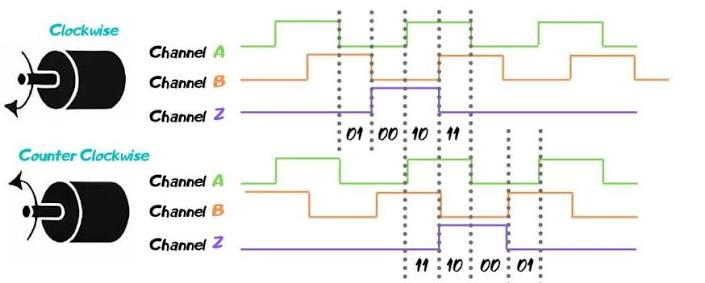

Suponga que los sensores contienen $N$ imanes y que los intervalos de tiempo donde las lecturas de los canales A y B coinciden y difieren son iguales y de duración $\Delta t$. La duración del intervalo donde un canal produce una señal lógica alta es $2\Delta t$ y un ciclo tiene duración $4\Delta t$.

Asumiendo que los imanes producen campos magnéticos alternantes sobre sectores circulares iguales, el desplazamiento angular (en radianes) ocupado por cada sector es:
$$\Delta \theta = \frac{2\pi}{N} \quad \text{ [rad]}$$

Por lo tanto, dado que el tiempo en que la dirección del campo magnético en uno de los sensores se mantiene es $2\Delta t$, la velocidad angular promedio medida durante este intervalo es:

$$\omega_m = \frac{\pi}{N \Delta t} \quad \text{ [rad/s]}$$

Usando periféricos temporizadores y capturadores de onda, podemos medir la duración de $\Delta t$ o alguno de sus múltiplos relevantes.

Por simetría radial, se puede deducir que un motor con encoder por sensores de efecto Hall debe tener un número par de imanes. En caso contrario, habrían dos polos de la misma polaridad adyacentes y el sensor no produciría pulsos uniformes. Por lo tanto, si durante un ciclo hay tantos polos 'salientes' como 'entrantes' a los sensores, es lógico que si contamos cuántas veces cambia la señal, el número de imanes es ese valor.

Los microcontroladores son muy buenos para contar cuántas veces ocurre un flanco de cierto tipo (flancos positivos o flancos negativos). Sea $n_F$ el número de flancos positivos que ocurre durante una revolución del eje del motor. A partir de este número fácilmente medible en la práctica, podemos calcular el número de imanes a través de:

$$N = \frac{n_F}{2}$$


## **2.2. Medición de la posición angular**
Dado que no se dispone de un canal de índice, se propone un esquema artesanal para medir la posición angular del eje. Después de un evento (e.g. el reinicio del microcontrolador) podemos iniciar un contador de flancos que cuente cuántas veces ocurre un *flanco de cualquier tipo (positivo o negativo)* en uno de los dos canales. Usando la cuadratura, podemos saber también en qué dirección gira el eje del motor. De esta forma, podemos incrementar o decrementar el contador según el signo de la velocidad angular. Finalmente, podemos multiplicar el contador de cambios por el desplazamiento angular por polo de la rueda del encoder calculado previamente (una constante del encoder) y obtener una estimación de la posición angular actual $\theta = C (\Delta \theta)$.

Para explicarlo mejor, se propone el siguiente pseudocódigo

CONSTANTE delta_theta
1. Inicialice INT $C$
2. Inicialice un PIN de entrada PIN_A
3. WHILE(TRUE):
4.      BOOL A_curr = READ(PIN_A) %Estado del pin A en la iteración actual
5.      IF(A_curr != A_prev):
            omega = MEDIR_VELOCIDAD_ANGULAR
            C = C + SIGN(omega)
            theta = C * delta_theta

Este método puede ser funcional siempre y cuándo el intervalo de tiempo entre dos lecturas del pin que monitorea el sensor de cuadratura sea significativamente menor al periodo de rotación del eje del rotor. Dado que las constantes de tiempo características mecánicas del sistemas on mucho mayores a las constantes de tiempo característicos de la parte eléctrica, esto es viable y factible.

Una observación importante acerca de este esquema es que la posición angular no está acotada entre $0$ y $2\pi$, y se permite que esta incremente más alla. Esto no ocasiona problema alguno dado que son ángulos que corresponden a varias revoluciones.

Un detalle interesante acerca de este esquema es que, porque los desplazamientos angulares donde la polaridad del campo magnético cambia son constantes sobre toda la rueda, *la magnitud de la posición angular se cuantiza*. Esto significa que cualquier posición angular es un múltiplo entero de $\Delta \theta$. Esto limita la resolución del problema y fuerza a no tratar a la velocidad angular como una cantidad continua.

Ahora sí, con esta discusión hecha, ya podemos entender cómo podemos aplicar los métodos de derivación numérica que estudiamos en el curso y algunos posibles retos a ser observados.

## **2.3. Aplicación de métodos de diferenciación numérica**
En este caso, lo que obtendremos del experimento son mediciones del tiempo y la posición angular estimada con el encoder. En otras palabras, para el dato $k$ tendremos un par de datos $(t_k, \theta_k)$. Podemos usar los métodos de diferencias finitas y otros más para aproximar la derivada la posición angular respecto del tiempo y así obtener la velocidad angular como una función del tiempo.


### *2.3.1. Diferencias finitas*
Para aquellos lectores que no estén familiarizados con el tema, los **métodos de diferencias finitas** estiman la derivada de una función a través de la pendiente de una recta secante. Para un dato $k$ tenemos tres formas de aproximar la derivada a través de estos métodos:

- **Diferencias finitas Hacia adelante** - Se utiliza el siguiente dato $k+1$ para estimar la derivada:
$$y' \approx \frac{y_{k+1}-y_k}{x_{k+1}-x_k}$$

- **Diferencias finitas Hacia atras** - Se utiliza el dato anterior $k-1$ para estimar la derivada:
$$y' \approx \frac{y_{k}-y_{k-1}}{x_{k}-x_{k-1}}$$

- **Diferencias finitas centradas** - Se utiliza el dato anterior $k-1$ y el siguiente $k+1$ para estimar la derivada:
$$y' \approx \frac{y_{k+1}-y_{k-1}}{x_{k+1}-x_{k-1}}$$


Los primeros dos métodos tienen un error $O(h)$, mientras que el método de diferencias finitas centradas tiene un error $O(h^2)$. Al usar un $h$ pequeño, el método de diferencias centradas tiene un error menor y por lo tanto es más preferido.

### *2.3.2. Extrapolación de Richardson*
La **extrapolación de Richardson** es otra manera de aproximar las derivadas, y utiliza series de Taylor para obtener una función $\Phi(h)$ tal que en la serie de Taylor el error asociado a $h^2$ del método de diferencias finitas se elimine al hacer la suma $\Phi(h) +\Phi(h/2)$. Esto hace que el error sea de orden $O(h^4)$. El método puede extenderse tanto como deseemos con tal de mejorar la exactitud del cálulo.

$$\frac{4}{3} \Phi\left(\frac{h}{2}\right) - \frac{1}{3} \Phi\left(h\right) = y'(x) + O(h^4)$$

Donde

$$\Phi\left(h\right) = \frac{y_{k+1}-y_{k-1}}{2h}$$

Sin embargo, este método supone que el paso es **uniforme**: la cancelación del término de error $O(h^2)$ depende de que las muestras $t_{j\pm k}$ y $t_{j\pm 2k}$ estén exactamente a distancias $h$ y $2h$ de $t_j$. Los tiempos medidos por el microcontrolador tienen *jitter* (el paso no es exactamente constante), así que en la práctica la cancelación es solo aproximada. Además, los coeficientes $4/3$ y $-1/3$ amplifican el ruido de cuantización de $\theta$, algo que se comprueba en la sección 2.5.

### *2.3.3. Conteo en ventana*
Interesantemente, en la guía del proyecto se propone un método adicional llamado el **método de conteo de ventana**. Al investigar más sobre este método, se encontró que básicamente consiste en contar el número de ocurrencias de un evento en un intervalo de tiempo y dividirla entre el intervalo para obtener la frecuencia de ocurrencias promedio.

Suponga que durante un intervalo de tiempo (una *ventana*) $W$ ocurren $n$ flancos positivos o negativos en uno de los canales del encoder. La tasa de cambios en la señal medida es entonces:

$$\text{tasa} = \frac{n}{W}$$

Al ajustar el tamaño de la ventana, la tasa resultante cambia.

### *2.3.4. Implementación en Python*



Las funciones de la celda siguiente aplican los métodos de diferencias finitas a datos tabulados $(t_j, y_j)$, por ejemplo la posición angular $\theta_j$ medida con el encoder en el instante $t_j$. El parámetro $k$ es la *ventana*: cuántas muestras se salta para formar la diferencia.

| Método | Fórmula en el índice $j$ | Error de truncamiento | ¿Causal? |
|---|---|---|---|
| Hacia adelante | $\dfrac{y_{j+k}-y_j}{t_{j+k}-t_j}$ | $O(h)$ | No |
| Hacia atrás | $\dfrac{y_j-y_{j-k}}{t_j-t_{j-k}}$ | $O(h)$ | **Sí** |
| Centrada | $\dfrac{y_{j+k}-y_{j-k}}{t_{j+k}-t_{j-k}}$ | $O(h^2)$ con paso uniforme; $O(h)$ si no | No |
| Richardson | $\dfrac{4\,D(k)-D(2k)}{3}$, con $D$ la centrada | $O(h^4)$ con paso uniforme | No |

- Contexto: Un método **causal** solo usa la muestra actual y las anteriores. Por eso la diferencia hacia atrás es la única que se puede calcular en tiempo real, por ejemplo dentro del lazo del control PID; las demás sirven para analizar los datos después del ensayo. En otras palabras: Un método es causal no necesita del vecino de adelante solo es que atrás y el del presente. Es no causal si necesita datos del futuro (t_{j+1}, …).
- Donde una fórmula necesita muestras que no existen (los bordes), el resultado es `NaN`. La función `derivada_sin_bordes` completa los bordes con las diferencias hacia adelante y hacia atrás.

*Funciones adaptadas del cuaderno de Grettel y Deyler (`Import/Proyecto3MotorDC.ipynb`), reorganizadas y documentadas con IA (Claude Opus 5.5, Anthropic).*

In [1]:
# =============================================================================
#  PARTE 2 · FUNCIONES DE DERIVACIÓN NUMÉRICA
# -----------------------------------------------------------------------------
#  Origen: cuaderno de Grettel y Deyler (Import/Proyecto3MotorDC.ipynb, celda 14).
#  Reorganizadas, documentadas y con validación de entradas por Claude Opus 5.5
#  (Anthropic), asistente de IA. Ver UsoIA/BitacoraUsoIA.md.
#
#  Todas las funciones reciben datos tabulados (t_j, y_j):
#    - t: tiempos de muestreo, estrictamente crecientes (pueden no ser uniformes);
#    - y: valores medidos, por ejemplo la posición angular θ del encoder.
#  Devuelven un arreglo del mismo tamaño que y. Donde la fórmula necesita
#  puntos que no existen (los bordes), el resultado es NaN.
#
#  El parámetro k es la "ventana": cuántas muestras se salta para formar la
#  diferencia. Con k = 1 se usan los vecinos inmediatos. Un k más grande reduce
#  el ruido de cuantización del encoder, pero suaviza y retrasa los cambios.
# =============================================================================
import numpy as np


def _validar(t, y, k, puntos_por_lado):
    """Convierte las entradas a arreglos y revisa que se pueda derivar.

    puntos_por_lado: cuántas muestras necesita la fórmula a cada lado (k o 2k).
    """
    t = np.asarray(t, dtype=float)
    y = np.asarray(y, dtype=float)
    if t.ndim != 1 or t.shape != y.shape:
        raise ValueError("t y y deben ser arreglos de una dimensión y del mismo tamaño.")
    if not (isinstance(k, (int, np.integer)) and k >= 1):
        raise ValueError("La ventana k debe ser un entero mayor o igual a 1.")
    if len(t) <= puntos_por_lado:
        raise ValueError(f"Se necesitan más de {puntos_por_lado} muestras para esta ventana.")
    if np.any(np.diff(t) <= 0):
        raise ValueError("t debe ser estrictamente creciente (revise muestras repetidas o desordenadas).")
    return t, y


def d_adelante_k(t, y, k=1):
    """Diferencia hacia adelante:  y'(t_j) ≈ (y_{j+k} - y_j) / (t_{j+k} - t_j).

    Error de truncamiento O(h). No es causal: usa una muestra futura, así que
    solo sirve para análisis fuera de línea. Las últimas k muestras quedan en NaN.
    """
    t, y = _validar(t, y, k, k)
    d = np.full(len(y), np.nan)
    d[:-k] = (y[k:] - y[:-k]) / (t[k:] - t[:-k])
    return d


def d_atras_k(t, y, k=1):
    """Diferencia hacia atrás:  y'(t_j) ≈ (y_j - y_{j-k}) / (t_j - t_{j-k}).

    Error de truncamiento O(h). Es causal: solo usa la muestra actual y las
    pasadas, por lo que es la única de estas fórmulas que se puede calcular en
    tiempo real (por ejemplo, dentro del lazo del PID). Es el "conteo en
    ventana" del encoder. Las primeras k muestras quedan en NaN.
    """
    t, y = _validar(t, y, k, k)
    d = np.full(len(y), np.nan)
    d[k:] = (y[k:] - y[:-k]) / (t[k:] - t[:-k])
    return d


def d_centrada_k(t, y, k=1):
    """Diferencia centrada:  y'(t_j) ≈ (y_{j+k} - y_{j-k}) / (t_{j+k} - t_{j-k}).

    Error de truncamiento O(h^2) si el paso es uniforme. Si el paso no es
    uniforme, los términos de error no se cancelan y el orden baja a O(h).
    No es causal. Las primeras y las últimas k muestras quedan en NaN.
    """
    t, y = _validar(t, y, k, 2 * k)
    d = np.full(len(y), np.nan)
    d[k:-k] = (y[2 * k:] - y[:-2 * k]) / (t[2 * k:] - t[:-2 * k])
    return d


def d_richardson(t, y, k=1):
    """Extrapolación de Richardson sobre la diferencia centrada:

        y'(t_j) ≈ [4·D(k) - D(2k)] / 3,

    donde D(k) es la centrada con ventana k y D(2k) la centrada con el doble
    de ventana. Combinar las dos cancela el término de error O(h^2) y deja un
    error O(h^4). Supone paso uniforme: con paso irregular la cancelación no es
    exacta. No es causal. Las primeras y las últimas 2k muestras quedan en NaN.
    """
    return (4.0 * d_centrada_k(t, y, k) - d_centrada_k(t, y, 2 * k)) / 3.0


def derivada_sin_bordes(t, y, k=1):
    """Derivada en todas las muestras, sin NaN en los bordes.

    Usa la centrada con ventana k en el interior; en las primeras muestras usa
    la diferencia hacia adelante y en las últimas, hacia atrás (misma ventana).
    Reemplaza a omega_completa del cuaderno original, que dependía de una
    variable global (K_VENTANA) y de un DataFrame.
    """
    d = d_centrada_k(t, y, k)
    adelante, atras = d_adelante_k(t, y, k), d_atras_k(t, y, k)
    return np.where(np.isnan(d), np.where(np.isnan(adelante), atras, adelante), d)


# Métodos disponibles, con la ventana mínima (k = 1). Útil para recorrerlos en un ciclo.
METODOS_DERIVACION = {
    "Hacia adelante": d_adelante_k,
    "Hacia atrás": d_atras_k,
    "Centrada": d_centrada_k,
    "Richardson": d_richardson,
}


#### **Verificación con una función conocida**
Antes de aplicarlas a las mediciones, se comprueba que cada función tenga el orden de error esperado. Se deriva $y = \sin x$, cuya derivada exacta es $\cos x$, con pasos $h$ cada vez más pequeños: si el error es $O(h^p)$, al reducir $h$ a la mitad el error se divide entre $2^p$.

In [2]:
# =============================================================================
#  Verificación de las funciones de derivación con una función conocida
# -----------------------------------------------------------------------------
#  Se deriva y = sin(x), cuya derivada exacta es cos(x), con pasos h cada vez
#  más pequeños. Si un método tiene error O(h^p), al reducir h a la mitad el
#  error se divide entre 2^p, así que el orden observado es
#      p ≈ log2( error(h) / error(h/2) ).
#  Se espera p ≈ 1 (adelante y atrás), p ≈ 2 (centrada) y p ≈ 4 (Richardson).
#  Origen: verificar_derivadas del cuaderno de Grettel y Deyler (celda 30).
# =============================================================================


def verificar_derivadas(hs=(0.2, 0.1, 0.05, 0.025)):
    """Devuelve los errores máximos |D - cos(x)| y el orden observado para cada método."""
    errores = {nombre: [] for nombre in METODOS_DERIVACION}
    for h in hs:
        x = np.arange(0.0, 6.0 + h / 2, h)          # malla uniforme en [0, 6]
        exacta = np.cos(x)
        for nombre, metodo in METODOS_DERIVACION.items():
            # nanmax ignora los bordes, donde la fórmula devuelve NaN
            errores[nombre].append(np.nanmax(np.abs(metodo(x, np.sin(x)) - exacta)))
    ordenes = {nombre: np.log2(np.array(e[:-1]) / np.array(e[1:])) for nombre, e in errores.items()}
    return errores, ordenes


hs = (0.2, 0.1, 0.05, 0.025)
errores, ordenes = verificar_derivadas(hs)

print("Error máximo |D - cos(x)|")
print(f"{'h':>7} " + " ".join(f"{nombre:>15}" for nombre in METODOS_DERIVACION))
for i, h in enumerate(hs):
    print(f"{h:>7.3f} " + " ".join(f"{errores[n][i]:>15.3e}" for n in METODOS_DERIVACION))

print("\nOrden observado p  (se espera 1, 1, 2 y 4)")
for i in range(len(hs) - 1):
    print(f"{hs[i]:>5.3f}->{hs[i + 1]:<5.3f}" + " ".join(f"{ordenes[n][i]:>15.2f}" for n in METODOS_DERIVACION))
    

Error máximo |D - cos(x)|
      h  Hacia adelante     Hacia atrás        Centrada      Richardson
  0.200       9.978e-02       9.987e-02       6.642e-03       5.299e-05
  0.100       4.998e-02       4.999e-02       1.664e-03       3.326e-06
  0.050       2.500e-02       2.500e-02       4.166e-04       2.083e-07
  0.025       1.250e-02       1.250e-02       1.042e-04       1.302e-08

Orden observado p  (se espera 1, 1, 2 y 4)
0.200->0.100           1.00            1.00            2.00            3.99
0.100->0.050           1.00            1.00            2.00            4.00
0.050->0.025           1.00            1.00            2.00            4.00


## **2.4. Datos del experimento**
Para aplicar las funciones de la sección 2.3 se necesitan mediciones $(t_j, V_j, i_j, \text{pulsos}_j)$ de cada prueba: escalones de voltaje y desaceleraciones libres, con y sin el disco acoplado al eje. La posición angular se reconstruye con el esquema de la sección 2.2:

$$\theta_j = \frac{\text{pulsos}_j}{\text{pulsos por vuelta}}\,2\pi$$

Mientras el Excel `mediciones_motor_dc.xlsx` no tenga datos reales, el cuaderno genera **datos de demostración** con exactamente el mismo formato. Se simula el motor de la Introducción (ver abajo) y se le agregan las imperfecciones de la medición real:

- **Ruido** en $V$ e $i$.
- ***Jitter*** en el tiempo: $t_j = j/f_s + \text{ruido}$, de modo que el paso no es uniforme.
- **Cuantización** de $\theta$: el encoder solo entrega múltiplos de $\Delta\theta = 2\pi/\text{ppv}$ (sección 2.3).

La ventaja de los datos sintéticos es que se conoce la verdad ($\omega$, $\theta$ e $i$ sin ruido), así que se puede medir cuánto error introduce cada método. Cuando existan datos reales se usan automáticamente.

*Sección adaptada del cuaderno de Grettel y Deyler y redactada con IA (Claude Sonnet 5.5, Anthropic), Ver `UsoIA/BitacoraUsoIA.md`.*

#### **Configuración**

In [3]:
# =============================================================================
#  CONFIGURACIÓN DE LA PARTE EXPERIMENTAL (derivación e integración)
# -----------------------------------------------------------------------------
#  Origen: cuaderno de Grettel y Deyler, celdas 6 y 8).
#  Integrada a este cuaderno con ayuda de IA (Claude Sonnet 5.5, Anthropic).
# =============================================================================
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.interpolate import CubicSpline
from scipy.integrate import simpson as simpson_scipy   # solo para verificar nuestro Simpson
from numpy.polynomial.legendre import leggauss

plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.float_format", lambda v: f"{v:.6g}")
rng = np.random.default_rng(23586)       # semilla fija: los datos de demostración son reproducibles

ARCHIVO   = Path("mediciones_motor_dc.xlsx")   # Excel con las hojas Parametros / Pruebas / Datos
USAR_DEMO = None    # None = automático (demo si el Excel no tiene datos) | True = forzar demo | False = forzar Excel
L_HENRY   = 2e-3    # inductancia del devanado [H]. No está en el Excel: medirla (LCR) o estimarla del transitorio de i(t)
K_VENTANA = 5       # ventana (en muestras) para derivar la posición del encoder; se justifica en la sección 2.5


#### **Motor sintético**
La función `f_motor` es el campo vectorial $\mathbf{f}$ del sistema de la Introducción, con $\text{sign}(\omega)$ sustituida por $\tanh(\omega/\varepsilon)$, la regularización de la sección 1.4. Se resuelve con el método de Euler explícito y con RK4, con un paso interno $h \ll L/R$ para que el método explícito sea estable. La verificación de la última línea compara ambos contra la velocidad estacionaria analítica (con $\tanh \approx 1$):

$$\omega_{ss} = \frac{K_t V/R - \tau_c}{b + K_t K_e/R}$$

Aquí la simulación solo sirve para **generar datos con verdad conocida**; el análisis de Euler contra RK4 es parte de la Parte 1.

In [4]:
# =============================================================================
#  MOTOR SINTÉTICO: modelo de la Parte 1 resuelto con RK4 (referencia "verdad")
# -----------------------------------------------------------------------------
#  Mismo sistema de EDOs de la Introducción, con sign(ω) regularizada por
#  tanh(ω/ε) (sección 1.4) para que el integrador no sufra en ω = 0.
#  Estado x = [i, ω, θ]. Origen: celdas 10 y 21 del cuaderno de Grettel y Deyler.
# =============================================================================
import math

# Motor "verdadero" de la demostración (SI). Con datos reales estos valores se estiman (sección 3.8).
DEMO = dict(R=2.0, L=2e-3, Ke=0.05, Kt=0.05, J=2e-5, b=1e-4, tauc=5e-3,
            ppv=44.0,                      # pulsos por vuelta del eje (11 PPR x 4 flancos)
            masa_disco=0.05, radio_disco=0.03, fs=500.0)
P_VERDAD = dict(R=DEMO["R"], L=DEMO["L"], Ke=DEMO["Ke"], Kt=DEMO["Kt"], J=DEMO["J"],
                b=DEMO["b"], tauc=DEMO["tauc"], tau_carga=0.0, eps=0.5)


def f_motor(x, V, P, coast=False):
    """Campo vectorial f(x) del motor, con x = [i, ω, θ]. coast=True: devanado abierto (i = 0)."""
    i, w, th = x
    fric = P["b"] * w + P["tauc"] * math.tanh(w / P["eps"])
    if coast:
        return np.array([0.0, -(fric + P["tau_carga"]) / P["J"], w])
    di = (V - P["R"] * i - P["Ke"] * w) / P["L"]
    dw = (P["Kt"] * i - fric - P["tau_carga"]) / P["J"]
    return np.array([di, dw, w])


def paso_euler(x, V, P, h, coast):
    return x + h * f_motor(x, V, P, coast)


def paso_rk4(x, V, P, h, coast):
    k1 = f_motor(x, V, P, coast)
    k2 = f_motor(x + 0.5 * h * k1, V, P, coast)
    k3 = f_motor(x + 0.5 * h * k2, V, P, coast)
    k4 = f_motor(x + h * k3, V, P, coast)
    return x + h / 6.0 * (k1 + 2 * k2 + 2 * k3 + k4)


def simular(P, t_eval, V_fun, x0=(0.0, 0.0, 0.0), metodo="rk4", h_max=2e-4, t_corte=None):
    """Integra el motor y devuelve una matriz (len(t_eval), 3) con columnas [i, ω, θ].

    V_fun(t): voltaje aplicado. t_corte: instante en que se abre el circuito
    (desaceleración libre). h_max: paso interno máximo; con h_max << L/R el
    método explícito es estable (ver sección 1.4)."""
    paso = paso_rk4 if metodo == "rk4" else paso_euler
    x = np.array(x0, float)
    out = np.empty((len(t_eval), 3)); out[0] = x
    for k in range(len(t_eval) - 1):
        t0, t1 = t_eval[k], t_eval[k + 1]
        n = max(1, int(np.ceil((t1 - t0) / h_max))); h = (t1 - t0) / n
        for j in range(n):
            t = t0 + j * h
            coast = (t_corte is not None) and (t >= t_corte)
            if coast and x[0] != 0.0:
                x = x.copy(); x[0] = 0.0          # al abrir el circuito la corriente cae a 0
            x = paso(x, V_fun(t), P, h, coast)
        out[k + 1] = x
    return out


# Verificación rápida: escalón de 6 V contra la velocidad estacionaria analítica (tanh ≈ 1)
Vt = 6.0
t_chk = np.arange(0, 1.0, 0.002)
X_rk4 = simular(P_VERDAD, t_chk, lambda s: Vt, metodo="rk4")
X_eul = simular(P_VERDAD, t_chk, lambda s: Vt, metodo="euler")
w_ss = (P_VERDAD["Kt"] * Vt / P_VERDAD["R"] - P_VERDAD["tauc"]) / (P_VERDAD["b"] + P_VERDAD["Kt"] * P_VERDAD["Ke"] / P_VERDAD["R"])
print(f"ω estacionaria analítica = {w_ss:.3f} rad/s | RK4 = {X_rk4[-1, 1]:.3f} | Euler = {X_eul[-1, 1]:.3f}")


ω estacionaria analítica = 107.407 rad/s | RK4 = 107.407 | Euler = 107.407


#### **Carga y validación de los datos**
La función `validar_tests` revisa que el tiempo sea creciente, que no haya `NaN` y que el conteo de pulsos no decrezca, y estima la frecuencia de muestreo y el *jitter* de cada prueba.

Hoja 'Parametros' leída de mediciones_motor_dc.xlsx


► Usando datos reales de mediciones_motor_dc.xlsx: 14 pruebas.


,tipo,carga,Vnom
id,,,
E_SC_1,Escalón,Sin carga,3.012
E_SC_2,Escalón,Sin carga,5.412
E_SC_3,Escalón,Sin carga,7.812
E_SC_4,Escalón,Sin carga,10.212
E_SC_5,Escalón,Sin carga,12
D_SC_1,Desaceleración libre,Sin carga,12
D_SC_2,Desaceleración libre,Sin carga,7.812
E_CC_1,Escalón,Con disco,3.012
E_CC_2,Escalón,Con disco,5.412


,n,dur_s,fs_Hz,jitter_pct,V_max,i_max,pulsos_fin,estado
id,,,,,,,,
E_SC_1,6680,3.29943,2024.29,2.85528e-11,3.012,0.4071,2479,OK
E_SC_2,6680,3.29943,2024.29,2.85528e-11,5.412,0.723,4596,OK
E_SC_3,6680,3.29943,2024.29,2.85528e-11,7.812,0.8872,5553,OK
E_SC_4,6680,3.29943,2024.29,2.85528e-11,10.212,1.0371,6072,OK
E_SC_5,6680,3.29943,2024.29,2.85528e-11,12,1.4256,6516,OK
D_SC_1,9716,4.79921,2024.29,4.33806e-11,12,1.2207,6512,OK
D_SC_2,9716,4.79921,2024.29,4.33806e-11,7.812,0.8824,5606,OK
E_CC_1,6672,3.29547,2024.29,2.85275e-11,3.012,0.4124,2628,OK
E_CC_2,6680,3.29943,2024.29,2.85528e-11,5.412,0.7398,4858,OK


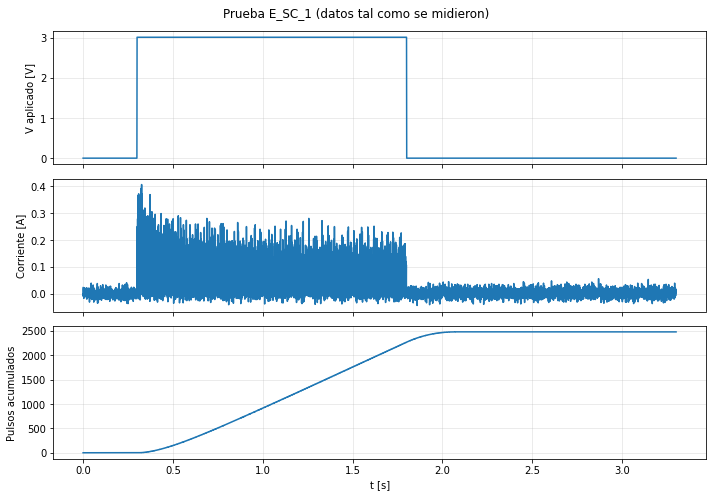

In [5]:
# =============================================================================
#  DATOS DEL EXPERIMENTO: Excel real o datos de demostración
# -----------------------------------------------------------------------------
#  Formato (hoja "Datos"): ID prueba, tiempo (s), V aplicado (V), corriente (A),
#  pulsos acumulados del encoder. La posición se calcula como
#      θ = pulsos / (pulsos por vuelta) · 2π.
#  Si el Excel no tiene datos, se simula el motor y se agrega ruido a V e i,
#  jitter al tiempo y cuantización de θ a la resolución del encoder.
#  Origen: celdas 8, 10, 24 y 25 del cuaderno de Grettel y Deyler.
# =============================================================================
def leer_hoja_parametros(archivo):
    df = pd.read_excel(archivo, sheet_name="Parametros", header=2)
    df = df.dropna(subset=["Parámetro"])
    return dict(zip(df["Parámetro"].astype(str), df["Valor"]))


def _num(raw, clave):
    """Valor numérico de la primera fila cuyo nombre contiene `clave` (NaN si no hay)."""
    for nombre, v in (raw or {}).items():
        if clave.lower() in nombre.lower():
            try:
                v = float(v)
                return v if np.isfinite(v) else np.nan
            except (TypeError, ValueError):
                return np.nan
    return np.nan


def construir_cfg(raw):
    """Diccionario de configuración; lo que falte en el Excel se completa con DEMO."""
    cfg, faltan = {}, []
    def tomar(nombre, clave, demo):
        v = _num(raw, clave)
        if not np.isfinite(v):
            faltan.append(nombre); v = demo
        cfg[nombre] = v
    tomar("R", "promedio", DEMO["R"])
    tomar("ppv", "Pulsos por vuelta", DEMO["ppv"])
    tomar("masa_disco", "Masa del disco", DEMO["masa_disco"])
    tomar("radio_disco", "Radio del disco", DEMO["radio_disco"])
    tomar("fs", "Frecuencia de muestreo", DEMO["fs"])
    cfg["L"] = L_HENRY
    cfg["J_disco"] = 0.5 * cfg["masa_disco"] * cfg["radio_disco"] ** 2     # disco sólido: J = m r² / 2
    return cfg, faltan


def inferir_meta(id_):
    u = id_.upper()
    return dict(tipo="Escalón" if u.startswith("E") else "Desaceleración libre",
                carga="Con disco" if "CC" in u else "Sin carga", Vnom=np.nan)


def cargar_datos_excel(archivo, cfg):
    d = pd.read_excel(archivo, sheet_name="Datos")
    d = d.rename(columns={"ID prueba": "id", "Tiempo (s)": "t", "V aplicado (V)": "V", "Corriente (A)": "i",
                          "Pulsos encoder (acumulados)": "pulsos", "Notas": "notas"})
    d = d[["id", "t", "V", "i", "pulsos", "notas"]]
    d = d[~d["notas"].astype(str).str.contains("EJEMPLO", case=False, na=False)]
    d = d.dropna(subset=["id", "t", "V", "i", "pulsos"])
    if d.empty:
        return {}, pd.DataFrame()
    d["theta"] = d["pulsos"] / cfg["ppv"] * 2 * np.pi
    tests = {k: g.drop(columns=["id", "notas"]).reset_index(drop=True) for k, g in d.groupby("id", sort=False)}
    try:
        m = pd.read_excel(archivo, sheet_name="Pruebas", header=2)
        m = m.rename(columns={"ID prueba": "id", "Tipo": "tipo", "Carga": "carga", "Voltaje nominal (V)": "Vnom",
                              "Frecuencia muestreo real (Hz)": "fs", "Duración (s)": "dur"}).dropna(subset=["id"])
        m = m.set_index("id")
    except Exception:
        m = pd.DataFrame()
    filas = []
    for k in tests:
        base = inferir_meta(k)
        if k in m.index:
            for c in ("tipo", "carga", "Vnom"):
                if c in m.columns and pd.notna(m.loc[k, c]):
                    base[c] = m.loc[k, c]
        base["id"] = k
        filas.append(base)
    return tests, pd.DataFrame(filas).set_index("id")


def simular_prueba(P, ppv, V_fun, t_fin, fs, t_corte=None, jitter=20e-6, ruido_V=0.01, ruido_i=0.015):
    """Prueba sintética con el formato del Excel (+ columnas de 'verdad': omega_true, theta_true, i_true)."""
    n = int(round(t_fin * fs)) + 1
    t = np.arange(n) / fs + rng.normal(0, jitter, n)      # jitter: el micro no muestrea perfecto
    t[0] = 0.0
    X = simular(P, t, V_fun, t_corte=t_corte)
    th = X[:, 2]
    d = pd.DataFrame(dict(t=t,
                          V=np.array([V_fun(s) for s in t]) + rng.normal(0, ruido_V, n),
                          i=X[:, 0] + rng.normal(0, ruido_i, n),
                          pulsos=np.floor(th * ppv / (2 * np.pi)).astype(int)))   # cuantización del encoder
    d["theta"] = d["pulsos"] / ppv * 2 * np.pi
    d["omega_true"], d["theta_true"], d["i_true"] = X[:, 1], th, X[:, 0]
    return d


def generar_demo(cfg, P_verdad, fs=500.0):
    plan = []
    for carga, cc in (("Sin carga", "SC"), ("Con disco", "CC")):
        plan += [(f"E_{cc}_{k}", "Escalón", carga, V) for k, V in enumerate([3, 6, 9, 12], 1)]
        plan += [(f"D_{cc}_{k}", "Desaceleración libre", carga, V) for k, V in enumerate([6, 12], 1)]
    tests, filas = {}, []
    for id_, tipo, carga, Vn in plan:
        P = dict(P_verdad)
        if carga == "Con disco":
            P["J"] += cfg["J_disco"]
        if tipo == "Escalón":
            V_fun = (lambda s, Vn=Vn: Vn if s >= 0.1 else 0.0); t_fin, t_corte = 1.6, None
        else:
            V_fun = (lambda s, Vn=Vn: Vn if s < 1.2 else 0.0);  t_fin, t_corte = 2.0, 1.2
        tests[id_] = simular_prueba(P, cfg["ppv"], V_fun, t_fin, fs, t_corte)
        filas.append(dict(id=id_, tipo=tipo, carga=carga, Vnom=Vn))
    return tests, pd.DataFrame(filas).set_index("id")


def estimar_fs(t):
    """Frecuencia de muestreo mediana [Hz] y jitter (desv. est. de Δt relativa a su mediana, en %)."""
    dt = np.diff(t)
    return 1.0 / np.median(dt), 100.0 * np.std(dt) / np.median(dt)


def validar_tests(tests):
    filas = []
    for k, d in tests.items():
        t = d["t"].to_numpy(); prob = []
        if np.any(np.diff(t) <= 0): prob.append("t no creciente")
        if d[["t", "V", "i", "pulsos"]].isna().any().any(): prob.append("hay NaN")
        retro = -np.diff(d["pulsos"].to_numpy())
        # Al detenerse, el eje puede rebotar y retroceder 1 o 2 cuentas: eso es real, no un error.
        # Solo se marca si retrocede más de 2 cuentas de golpe.
        if np.any(retro > 2): prob.append("pulsos retroceden > 2 cuentas")
        fs, jit = estimar_fs(t)
        filas.append(dict(id=k, n=len(d), dur_s=t[-1] - t[0], fs_Hz=fs, jitter_pct=jit,
                          V_max=d["V"].max(), i_max=d["i"].max(), pulsos_fin=int(d["pulsos"].iloc[-1]),
                          estado="; ".join(prob) or "OK"))
    return pd.DataFrame(filas).set_index("id")


def graficar_prueba(d, titulo=""):
    fig, ax = plt.subplots(3, 1, sharex=True, figsize=(10, 7))
    ax[0].plot(d["t"], d["V"]);                      ax[0].set_ylabel("V aplicado [V]")
    ax[1].plot(d["t"], d["i"]);                      ax[1].set_ylabel("Corriente [A]")
    ax[2].step(d["t"], d["pulsos"], where="post");   ax[2].set_ylabel("Pulsos acumulados")
    ax[2].set_xlabel("t [s]"); fig.suptitle(titulo); plt.tight_layout(); plt.show()


# ----- Fuente de datos: Excel real si tiene datos, demostración en caso contrario -----
raw = None
try:
    raw = leer_hoja_parametros(ARCHIVO)
    print(f"Hoja 'Parametros' leída de {ARCHIVO}")
except Exception as e:
    print(f"No se pudo leer {ARCHIVO} ({type(e).__name__}). Se usarán valores de demostración.")
cfg, faltan = construir_cfg(raw)
if faltan:
    print("Sin dato en el Excel (se usó el valor de demo):", faltan)

tests_x, meta_x = {}, None
try:
    tests_x, meta_x = cargar_datos_excel(ARCHIVO, cfg)
except Exception as e:
    print(f"No se pudieron leer datos de {ARCHIVO} ({type(e).__name__})")

usar_demo = (len(tests_x) == 0) if USAR_DEMO is None else USAR_DEMO
if usar_demo:
    print("► Usando DATOS DE DEMOSTRACIÓN (simulados). Se ignoran los parámetros del Excel.")
    cfg = dict(R=DEMO["R"], ppv=DEMO["ppv"], masa_disco=DEMO["masa_disco"], radio_disco=DEMO["radio_disco"],
               fs=DEMO["fs"], L=DEMO["L"], J_disco=0.5 * DEMO["masa_disco"] * DEMO["radio_disco"] ** 2)
    tests, meta = generar_demo(cfg, P_VERDAD, fs=cfg["fs"])
else:
    print(f"► Usando datos reales de {ARCHIVO}: {len(tests_x)} pruebas.")
    tests, meta = tests_x, meta_x

display(meta)
resumen = validar_tests(tests)
display(resumen)
assert (resumen["estado"] == "OK").all(), "Hay pruebas con problemas: revisar la columna 'estado'"
if (resumen["fs_Hz"] < 450).any():
    print("Alguna prueba muestrea a menos de ~500 Hz; la derivación del encoder será más ruidosa.")

id_ej = next(k for k in tests if meta.loc[k, "tipo"] == "Escalón")
graficar_prueba(tests[id_ej], f"Prueba {id_ej} (datos tal como se midieron)")


## **2.5. Elección de la ventana $k$: ruido de cuantización contra retraso**
Sea $\Delta\theta = 2\pi/\text{ppv}$ la resolución del encoder y $\Delta t$ el periodo de muestreo. La posición medida es $\theta^q_j = \theta_j - e_j$ con $0 \le e_j < \Delta\theta$ (el encoder trunca al último pulso). Al derivar con una diferencia de ventana $k$ aparecen dos errores que compiten:

1. **Ruido de cuantización.** El numerador resta dos errores $e_j$, cada uno en $[0, \Delta\theta)$, así que su diferencia está acotada por $\Delta\theta$ y

$$|\varepsilon_{\text{cuant}}| < \frac{\Delta\theta}{\text{ancho de la ventana}}, \qquad \text{ancho} = k\,\Delta t \ \text{(hacia atrás)}, \quad 2k\,\Delta t \ \text{(centrada)}$$

   Crece al achicar $k$. Con $\text{ppv}=44$ y $\Delta t = 2$ ms, un solo pulso equivale a $\Delta\theta/\Delta t \approx 71$ rad/s: con $k=1$ la señal es casi ruido.

2. **Error de truncamiento y retraso.** La diferencia hacia atrás con ventana $k$ en realidad estima la derivada en el punto medio $t_j - k\Delta t/2$, es decir, **retrasa** la señal $k\Delta t/2$ y comete un error $\approx \tfrac{k\Delta t}{2}\,\omega'(t)$, que es grande en el transitorio, donde $\omega'$ es grande. La centrada no tiene retraso y su error es $O\big((k\Delta t)^2\big)$. Crece al agrandar $k$.

El valor de $k$ es el compromiso entre ambos. En la celda siguiente se simula un escalón de 12 V, se cuantiza $\theta$ y se compara cada derivada con la $\omega$ verdadera en el **transitorio** (justo después del escalón, domina el retraso) y en el **estacionario** (domina el ruido de cuantización).

Richardson (k=1): RMSE transitorio = 15.030 | estacionario = 13.954 rad/s
Resolución del encoder: Δθ = 2π/44 = 0.1428 rad  → con k=1 y Δt = 2.0 ms, un solo pulso equivale a 71.4 rad/s


,rmse_atras_trans,rmse_atras_est,rmse_centrada_trans,rmse_centrada_est
k,,,,
1,20.2064,17.3865,11.6673,11.5657
2,14.0903,11.5539,6.7384,7.65952
3,13.5927,9.16052,5.52188,5.74783
5,17.7657,6.56084,5.43961,3.51213
8,25.069,4.46881,8.03527,0.852926
12,34.3369,2.66058,12.6766,1.49105
20,50.3864,1.45301,20.8315,0.885416
30,66.8358,0.924211,29.4784,0.578986


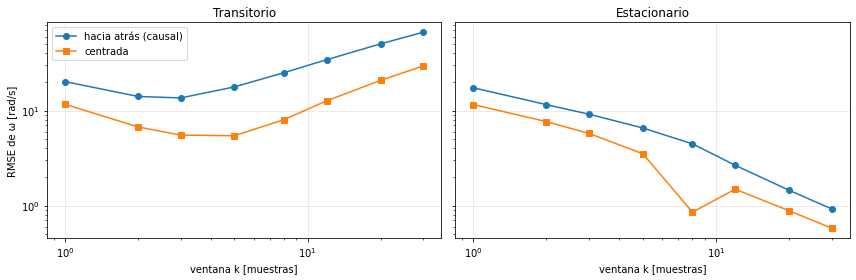

In [6]:
# =============================================================================
#  Compromiso de la ventana k: ruido de cuantización vs. retraso
# -----------------------------------------------------------------------------
#  Se simula un escalón de 12 V, se cuantiza θ y se compara cada derivada con
#  la ω verdadera (conocida porque la prueba es sintética) en dos zonas.
#  Origen: celda 32 del cuaderno de Grettel y Deyler.
# =============================================================================
def rmse(a, b):
    """Raíz del error cuadrático medio, ignorando los NaN de los bordes."""
    m = np.isfinite(a) & np.isfinite(b)
    return float(np.sqrt(np.mean((a[m] - b[m]) ** 2)))


d_exp = simular_prueba(P_VERDAD, cfg["ppv"], lambda s: 12.0 if s >= 0.1 else 0.0, t_fin=1.6, fs=cfg["fs"])
t_e, th_e, w_true = d_exp["t"].to_numpy(), d_exp["theta"].to_numpy(), d_exp["omega_true"].to_numpy()
zona_tr = (t_e >= 0.1) & (t_e < 0.25)       # transitorio: justo después del escalón
zona_ss = (t_e >= 0.8)                      # estacionario

filas = []
for k in [1, 2, 3, 5, 8, 12, 20, 30]:
    w_at, w_ce = d_atras_k(t_e, th_e, k), d_centrada_k(t_e, th_e, k)
    filas.append(dict(k=k,
                      rmse_atras_trans=rmse(w_at[zona_tr], w_true[zona_tr]),
                      rmse_atras_est=rmse(w_at[zona_ss], w_true[zona_ss]),
                      rmse_centrada_trans=rmse(w_ce[zona_tr], w_true[zona_tr]),
                      rmse_centrada_est=rmse(w_ce[zona_ss], w_true[zona_ss])))
tab_k = pd.DataFrame(filas).set_index("k")

w_r = d_richardson(t_e, th_e)
print(f"Richardson (k=1): RMSE transitorio = {rmse(w_r[zona_tr], w_true[zona_tr]):.3f} | "
      f"estacionario = {rmse(w_r[zona_ss], w_true[zona_ss]):.3f} rad/s")
print(f"Resolución del encoder: Δθ = 2π/{cfg['ppv']:.0f} = {2*np.pi/cfg['ppv']:.4f} rad  "
      f"→ con k=1 y Δt = {1/cfg['fs']*1e3:.1f} ms, un solo pulso equivale a {2*np.pi/cfg['ppv']*cfg['fs']:.1f} rad/s")
display(tab_k)

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, z, nom in zip(ax, ("trans", "est"), ("Transitorio", "Estacionario")):
    a.loglog(tab_k.index, tab_k[f"rmse_atras_{z}"], "o-", label="hacia atrás (causal)")
    a.loglog(tab_k.index, tab_k[f"rmse_centrada_{z}"], "s-", label="centrada")
    a.set_title(nom); a.set_xlabel("ventana k [muestras]")
ax[0].set_ylabel("RMSE de ω [rad/s]"); ax[0].legend(); plt.tight_layout(); plt.show()


Lectura de los resultados-  (datos de demostración con semilla fija; con las mediciones reales hay que repetir el análisis):

- **Hacia atrás.** En el estacionario el error baja al aumentar $k$ (menos ruido), pero en el transitorio sube desde $k\approx 2$ (más retraso). Para el mismo $k$ es peor que la centrada en el transitorio, justamente por el retraso de $k\Delta t/2$ y por su error $O(h)$ en lugar de $O(h^2)$.
- **Centrada.** El mejor compromiso queda alrededor de $k \approx 5$ (error de unos 5 rad/s en el transitorio y unos 3.5 rad/s en el estacionario), y por eso se fija `K_VENTANA = 5` en la celda de configuración.
- **Richardson con $k=1$.** No mejora a la centrada: con los datos de demostración su error es mayor (≈ 13 rad/s contra ≈ 11.6 rad/s en el estacionario). Su orden $O(h^4)$ solo se aprecia con datos suaves (como en la verificación con $\sin x$); con $\theta$ cuantizada domina el ruido, que los coeficientes $4/3$ y $-1/3$ amplifican.
- **Para el PID en línea** solo sirven los métodos **causales** (hacia atrás), que son justo los que sufren el compromiso más duro. Esto es lo que motiva la pregunta obligatoria sobre filtrar el término derivativo.

## **2.6. Aplicación a las mediciones**
Velocidad angular $\omega(t)$ obtenida de $\theta(t)$ con los distintos métodos, para el escalón de mayor voltaje y para una desaceleración libre. Abajo se amplía el instante del evento (la subida o el frenado).

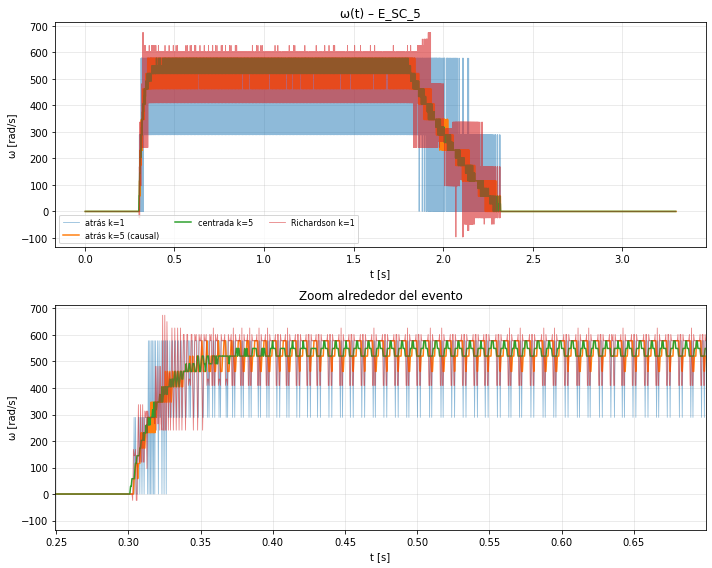

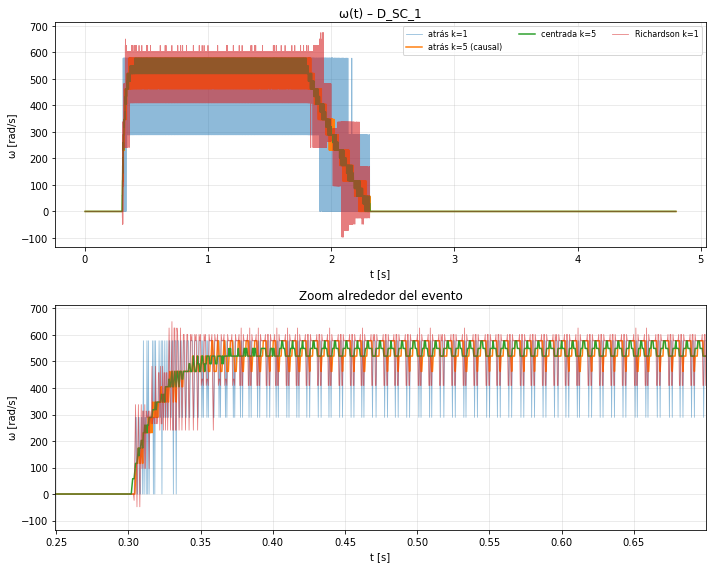

In [7]:
def graficar_omega(d, titulo, k=None):
    """ω(t) a partir de θ(t) con los distintos métodos; abajo, zoom sobre el evento (subida o frenado)."""
    k = k or K_VENTANA
    t, th = d["t"].to_numpy(), d["theta"].to_numpy()
    fig, ax = plt.subplots(2, 1, figsize=(10, 8))
    for a in ax:
        a.plot(t, d_atras_k(t, th, 1), lw=0.8, alpha=0.5, label="atrás k=1")
        a.plot(t, d_atras_k(t, th, k), label=f"atrás k={k} (causal)")
        a.plot(t, d_centrada_k(t, th, k), label=f"centrada k={k}")
        a.plot(t, d_richardson(t, th, 1), lw=0.8, alpha=0.6, label="Richardson k=1")
        if "omega_true" in d:
            a.plot(t, d["omega_true"], "k--", lw=1.2, label="ω verdadera (demo)")
        a.set_ylabel("ω [rad/s]")
    ax[0].set_title(titulo); ax[0].legend(ncol=3, fontsize=8)
    ax[0].set_xlabel("t [s]"); ax[1].set_xlabel("t [s]")
    V = d["V"].to_numpy()
    salto = np.abs(np.diff(V)) > 0.4 * np.abs(V).max()
    ev = t[np.argmax(salto)] if salto.any() else t[0]
    ax[1].set_xlim(ev - 0.05, ev + 0.4); ax[1].set_title("Zoom alrededor del evento")
    plt.tight_layout(); plt.show()


id_E = max((k for k in tests if meta.loc[k, "tipo"] == "Escalón"), key=lambda k: tests[k]["V"].max())
graficar_omega(tests[id_E], f"ω(t) – {id_E}")
ids_D = [k for k in tests if meta.loc[k, "tipo"] != "Escalón"]
if ids_D:
    graficar_omega(tests[ids_D[0]], f"ω(t) – {ids_D[0]}")
    

*Ojito, por ahora queda pendiente hasta cuando tengamos las mediciones reales: discutir si la $k$ elegida sigue siendo un buen compromiso con el ruido real del encoder, y cuánto retraso se observa en la desaceleración libre.* - grett


## **2.7. Error de cada método de derivación en función de $h$**

Como referencia "casi exacta" se usa Richardson con el paso más pequeño posible ($k=1$, $h = 1/f_s \approx 0.5$ ms) sobre la prueba con mayor velocidad. Luego se calcula, para cada método y cada ventana $k$ (paso $h = k/f_s$), el error máximo respecto de esa referencia. Hay que leerlo con cuidado: la referencia también tiene el ruido de cuantización, así que el "error" mezcla el error de truncamiento (que crece con $h$) y la diferencia en ruido (que baja con $h$).

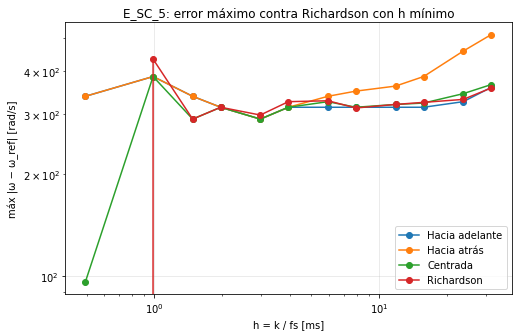

In [8]:
# =============================================================================
#  Error máximo de cada método de derivación contra Richardson con h mínimo
# =============================================================================
id_der = "E_SC_5" if "E_SC_5" in tests else list(tests)[0]
d_d = tests[id_der]; t_d, th_d = d_d["t"].to_numpy(), d_d["theta"].to_numpy()
fs_d = 1 / np.median(np.diff(t_d))
w_ref = d_richardson(t_d, th_d, k=1)
ks = np.array([1, 2, 3, 4, 6, 8, 12, 16, 24, 32, 48, 64])
err = {m: [] for m in METODOS_DERIVACION}
for k in ks:
    for m, f_der in METODOS_DERIVACION.items():
        w_k = f_der(t_d, th_d, k=int(k)); ok = np.isfinite(w_k) & np.isfinite(w_ref)
        err[m].append(np.max(np.abs(w_k[ok] - w_ref[ok])))
fig, ax = plt.subplots(figsize=(8, 5))
for m in err:
    ax.loglog(ks / fs_d * 1000, err[m], "o-", label=m)
ax.set_xlabel("h = k / fs [ms]"); ax.set_ylabel("máx |ω − ω_ref| [rad/s]")
ax.set_title(f"{id_der}: error máximo contra Richardson con h mínimo"); ax.legend(); plt.show()

## **2.8. Derivadas numéricas y conteo en ventana**

Abajo, la velocidad obtenida con todos los métodos para una misma ventana. Después, Richardson con el paso mínimo comparado con el *conteo en ventana* (pulsos contados en una ventana de $k$ muestras, divididos entre su duración) para varios tamaños de ventana: al crecer la ventana, el ruido de cuantización baja, pero la curva se retrasa y suaviza el transitorio.

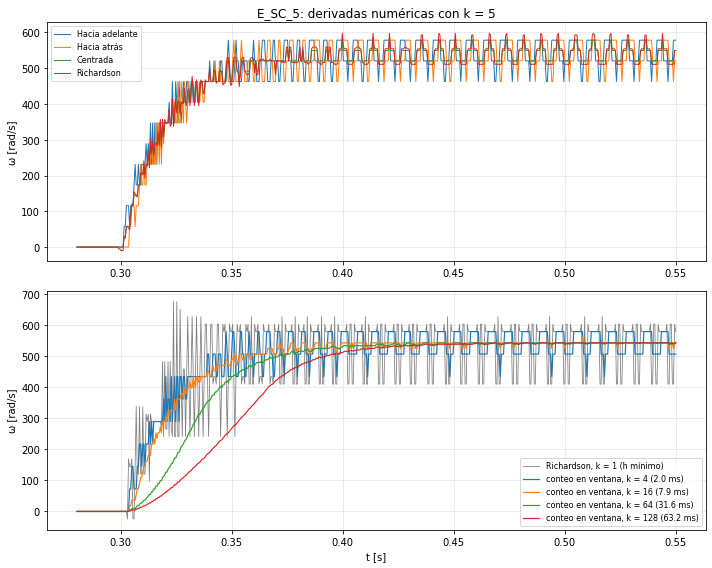

In [9]:
# =============================================================================
#  Derivadas numéricas y conteo en ventana
# =============================================================================
zoom = (t_d > t_d[np.argmax(d_d["V"].to_numpy() > 0)] - 0.02) & (t_d < t_d[np.argmax(d_d["V"].to_numpy() > 0)] + 0.25)
fig, ax = plt.subplots(2, 1, figsize=(10, 8))
for m, f_der in METODOS_DERIVACION.items():
    ax[0].plot(t_d[zoom], f_der(t_d, th_d, k=K_VENTANA)[zoom], lw=1, label=m)
ax[0].set_title(f"{id_der}: derivadas numéricas con k = {K_VENTANA}"); ax[0].set_ylabel("ω [rad/s]"); ax[0].legend(fontsize=8)

def conteo_ventana(t, th, k):
    # Pulsos contados en las últimas k muestras / duración de la ventana (hacia atrás, con retraso)
    w = np.full(len(th), np.nan); w[k:] = (th[k:] - th[:-k]) / (t[k:] - t[:-k]); return w

ax[1].plot(t_d[zoom], w_ref[zoom], color="0.5", lw=0.8, label="Richardson, k = 1 (h mínimo)")
for k in (4, 16, 64, 128):
    ax[1].plot(t_d[zoom], conteo_ventana(t_d, th_d, k)[zoom], lw=1.2, label=f"conteo en ventana, k = {k} ({1000*k/fs_d:.1f} ms)")
ax[1].set_xlabel("t [s]"); ax[1].set_ylabel("ω [rad/s]"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

# ***PARTE 3 - INTEGRACIÓN NUMÉRICA***
Ya se tiene $\omega(t)$ a partir de las mediciones. La segunda familia de herramientas del proyecto es la **integración numérica**, y en un motor DC aparece en cuatro lugares:

- **Energía:** la energía eléctrica consumida es $E_e = \int V\,i\,dt$ y permite hacer un balance de energía de cada prueba.
- **Parámetros:** el momento de inercia $J$ se estima con la **forma integral** de la ecuación mecánica, sin derivar dos veces datos ruidosos.
- **Geometría:** el momento de inercia de un disco se calcula integrando su perfil.
- **Control:** el término integral del PID acumula el error en el tiempo.

Los datos son **tabulados** $(t_j, y_j)$ y el paso no es uniforme, así que los métodos deben aceptar mallas irregulares. Se presentan tres: trapecio, Simpson 1/3 y Gauss-Legendre sobre un trazador cúbico.

*Sección adaptada del cuaderno de Grettel y Deyler (`Import/Proyecto3MotorDC.ipynb`) y redactada con IA (Claude Sonnet 5.5, Anthropic), a pedido de los autores. Ver `UsoIA/BitacoraUsoIA.md`.*

## **3.1. Regla del trapecio**
En cada subintervalo $[t_j, t_{j+1}]$ de ancho $h_j = t_{j+1}-t_j$ se reemplaza $y$ por el polinomio de grado 1 que pasa por los dos extremos (interpolación lineal). El área del trapecio resultante es

$$\int_{t_j}^{t_{j+1}} y\,dt \approx \frac{y_j + y_{j+1}}{2}\,h_j \qquad\Longrightarrow\qquad \int_{t_0}^{t_n} y\,dt \approx \sum_{j=0}^{n-1}\frac{y_j + y_{j+1}}{2}\,(t_{j+1}-t_j)$$

**Error.** Si $y \in C^2$, el error de la interpolación lineal es $y(t) - p_1(t) = \tfrac{1}{2}\,y''(\xi)\,(t - t_j)(t - t_{j+1})$. Al integrar sobre el subintervalo, el error local es $-\tfrac{h_j^3}{12}\,y''(\xi_j)$. Sumando $n$ subintervalos de ancho $h$ queda un error global

$$E_T = -\frac{(t_n - t_0)\,h^2}{12}\,y''(\bar\xi) = O(h^2)$$

Es exacta para polinomios de grado $\le 1$. Es la más simple, y como solo usa las muestras $j$ y $j+1$, también es la única que se puede **acumular en línea**: la integral hasta el instante $j$ no cambia cuando llegan muestras nuevas (función `trapecio_acum`).

## **3.2. Regla de Simpson 1/3**
Si en lugar de una recta se usa la **parábola** que pasa por tres puntos consecutivos $(t_0, y_0)$, $(t_1, y_1)$, $(t_2, y_2)$, se gana un orden de exactitud. Sean $h_1 = t_1 - t_0$ y $h_2 = t_2 - t_1$. Al integrar el polinomio de Lagrange de grado 2 sobre $[t_0, t_2]$ se obtiene, para una malla **no uniforme**,

$$\int_{t_0}^{t_2} y\,dt \approx \frac{h_1+h_2}{6}\left[\Big(2-\frac{h_2}{h_1}\Big)y_0 + \frac{(h_1+h_2)^2}{h_1 h_2}\,y_1 + \Big(2-\frac{h_1}{h_2}\Big)y_2\right]$$

Dos comprobaciones: los tres pesos suman $h_1 + h_2$ (la regla integra exactamente una constante), y si $h_1 = h_2 = h$ la expresión se reduce a la fórmula clásica $\tfrac{h}{3}\,(y_0 + 4y_1 + y_2)$.

**Error.** Con paso uniforme, el error local por cada par de subintervalos es $-\tfrac{h^5}{90}\,y^{(4)}(\xi)$ y el global es

$$E_S = -\frac{(t_n - t_0)\,h^4}{180}\,y^{(4)}(\bar\xi) = O(h^4)$$

La regla es exacta hasta para cúbicas cuando el paso es uniforme; con paso irregular solo se garantiza para parábolas. Como la fórmula consume los subintervalos de dos en dos, requiere un número **par** de subintervalos. Si sobra uno, el código lo cierra con trapecio, y como ese último trozo tiene error local $O(h^3)$ el orden global baja a $O(h^3)$. Conviene entonces usar un número par de subintervalos.

## **3.3. Gauss-Legendre sobre un trazador cúbico**
Las reglas anteriores usan solo los valores en las muestras. La **cuadratura de Gauss-Legendre** elige también *dónde* evaluar la función: con $m$ nodos $x_i$ y pesos $w_i$ en $[-1, 1]$ (los ceros del polinomio de Legendre $P_m$) es exacta para polinomios de grado $\le 2m-1$. Para un intervalo $[a, b]$ se hace el cambio de variable $t = \tfrac{a+b}{2} + \tfrac{b-a}{2}\,x$:

$$\int_a^b y\,dt \approx \frac{b-a}{2}\sum_{i=1}^{m} w_i\; y\!\left(\frac{a+b}{2} + \frac{b-a}{2}\,x_i\right)$$

El problema es que los nodos de Gauss no coinciden con las muestras. Con datos tabulados hay que **interpolar**: se construye el trazador cúbico natural $S(t)$ de los datos y se integra $S$ con Gauss-Legendre en cada subintervalo (opcionalmente subdividido en `n_sub` partes).

**Observación.** $S$ es un polinomio de grado 3 en cada subintervalo, y con $m = 2$ nodos Gauss-Legendre ya es exacta para grado $2m-1 = 3$. Por lo tanto, para este interpolante, $m=2$ y $m=5$ dan el mismo valor (se verifica en la sección 3.5): el resultado es la integral exacta del trazador, y su exactitud la fija el trazador, no el número de nodos.

## **3.4. Implementación en Python**
Las tres funciones reciben $(t, y)$ y devuelven la integral; el diccionario `METODOS_INTEGRACION` permite recorrerlas en un ciclo, igual que `METODOS_DERIVACION` en la Parte 2.

In [10]:
# =============================================================================
#  PARTE 3 · FUNCIONES DE INTEGRACIÓN NUMÉRICA
# -----------------------------------------------------------------------------
#  Origen: cuaderno de Grettel y Deyler (Import/Proyecto3MotorDC.ipynb, celda 16).
#  Se agregó validación de entradas y documentación (Claude Sonnet 5.5, Anthropic).
#
#  Todas reciben datos tabulados (t_j, y_j) con t estrictamente creciente; no
#  hace falta que el paso sea uniforme (el micro no muestrea perfecto).
# =============================================================================
def _validar_int(t, y, minimo=2):
    t = np.asarray(t, dtype=float)
    y = np.asarray(y, dtype=float)
    if t.ndim != 1 or t.shape != y.shape:
        raise ValueError("t y y deben ser arreglos de una dimensión y del mismo tamaño.")
    if len(t) < minimo:
        raise ValueError(f"Se necesitan al menos {minimo} muestras.")
    if np.any(np.diff(t) <= 0):
        raise ValueError("t debe ser estrictamente creciente (revise muestras repetidas o desordenadas).")
    return t, y


def trapecio(t, y):
    """Trapecio compuesto:  ∫ y dt ≈ Σ_j (y_j + y_{j+1})/2 · (t_{j+1} - t_j).  Error O(h²)."""
    t, y = _validar_int(t, y)
    return float(np.sum(0.5 * (y[1:] + y[:-1]) * np.diff(t)))


def trapecio_acum(t, y):
    """Integral acumulada ∫_{t_0}^{t_j} y dt para todo j (útil para graficar energía vs. tiempo).

    Es causal: el valor en j solo usa muestras hasta j, así que sirve también
    como término integral de un PID en línea."""
    t, y = _validar_int(t, y)
    return np.concatenate([[0.0], np.cumsum(0.5 * (y[1:] + y[:-1]) * np.diff(t))])


def simpson_compuesto(t, y):
    """Simpson 1/3 compuesto para malla NO uniforme (pares de subintervalos).  Error O(h⁴).

    Para cada par de subintervalos de anchos h1 y h2 integra la parábola que pasa
    por los tres puntos (fórmula de la sección 3.3). Si el número de subintervalos
    es impar, el último se cierra con trapecio y el orden global baja a O(h³)."""
    t, y = _validar_int(t, y, minimo=3)
    n = len(t) - 1
    m = n - (n % 2)                       # subintervalos que forman pares completos
    h = np.diff(t)
    h1, h2 = h[0:m:2], h[1:m:2]
    y0, y1, y2 = y[0:m:2], y[1:m:2], y[2:m + 1:2]
    total = np.sum((h1 + h2) / 6.0 * ((2 - h2 / h1) * y0
                                      + (h1 + h2) ** 2 / (h1 * h2) * y1
                                      + (2 - h1 / h2) * y2))
    if n % 2:                             # sobra un subintervalo -> trapecio
        total += 0.5 * (y[-1] + y[-2]) * h[-1]
    return float(total)


def gauss_legendre_spline(t, y, m=5, n_sub=1):
    """Gauss-Legendre de m nodos sobre el trazador cúbico natural S(t) de los datos.

    Cada subintervalo [t_j, t_{j+1}] se divide en n_sub partes y en cada parte
    ∫ S dt ≈ (b-a)/2 · Σ_i w_i S((a+b)/2 + (b-a)/2 · x_i), con (x_i, w_i) los
    nodos y pesos de Gauss-Legendre en [-1, 1]."""
    t, y = _validar_int(t, y, minimo=3)
    S = CubicSpline(t, y, bc_type="natural")
    nodos, pesos = leggauss(m)
    bordes = t[:-1, None] + (t[1:] - t[:-1])[:, None] * np.linspace(0, 1, n_sub + 1)[None, :]
    a, b = bordes[:, :-1].ravel(), bordes[:, 1:].ravel()
    medio, semi = (a + b) / 2, (b - a) / 2
    puntos = medio[:, None] + semi[:, None] * nodos[None, :]
    return float(np.sum(semi[:, None] * pesos[None, :] * S(puntos)))


METODOS_INTEGRACION = {"Trapecio": trapecio,
                       "Simpson 1/3": simpson_compuesto,
                       "Gauss-Legendre (spline)": gauss_legendre_spline}


## **3.5. Verificación con integrales conocidas**
Antes de usarlas con mediciones se comprueba el orden de cada método con $\int_0^\pi \sin x\,dx = 2$. Si el error es $O(h^p)$, al duplicar $n$ el error se divide entre $2^p$, así que el orden observado es $p \approx \log_2\big(e(h)/e(h/2)\big)$. Se espera $p = 2$ (trapecio) y $p = 4$ (Simpson); como referencia se incluye `scipy.integrate.simpson`, que debe coincidir con la versión propia en malla uniforme. Después se comprueba que el Simpson no uniforme integra exactamente una parábola sobre una malla irregular, y que Gauss-Legendre con $m=2$ y $m=5$ da lo mismo sobre el trazador.

In [11]:
# =============================================================================
#  Verificación de las funciones de integración con integrales conocidas
# -----------------------------------------------------------------------------
#  1) ∫_0^π sin x dx = 2 con n subintervalos: orden observado p = log2(e(h)/e(h/2)).
#  2) Simpson no uniforme debe ser EXACTO para polinomios de grado ≤ 2 aunque la
#     malla sea irregular (esto comprueba la fórmula con h1 ≠ h2).
#  Origen: tabla_verificacion_integral del cuaderno de Grettel y Deyler (celda 38).
# =============================================================================
def verificar_integrales(ns=(4, 8, 16, 32, 64)):
    """Errores |I - 2| de cada método y orden observado entre mallas consecutivas."""
    metodos = {**METODOS_INTEGRACION, "Simpson (scipy)": lambda x, y: float(simpson_scipy(y, x=x))}
    errores = {nom: [] for nom in metodos}
    for n in ns:
        x = np.linspace(0.0, np.pi, n + 1)
        for nom, f in metodos.items():
            errores[nom].append(abs(f(x, np.sin(x)) - 2.0))
    err = pd.DataFrame(errores, index=pd.Index(ns, name="n"))
    orden = pd.DataFrame(np.log2(err.iloc[:-1].to_numpy() / err.iloc[1:].to_numpy()),
                         index=err.index[:-1], columns=err.columns)
    return err, orden


err_i, orden_i = verificar_integrales()
print("Error absoluto |I - 2|"); display(err_i)
print("Orden observado p (se espera 2 para trapecio y 4 para Simpson)"); display(orden_i)

# --- Simpson no uniforme: exacto para parábolas aunque la malla sea irregular (h1 ≠ h2) ---
t_irr = np.sort(np.concatenate([[0.0, 2.0], rng.uniform(0.0, 2.0, 11)]))      # 13 puntos = 12 subintervalos (par)
cuad = lambda x: 1.0 + 2.0 * x - 3.0 * x ** 2
exacta = 1.0 * 2 + 2.0 * 2 ** 2 / 2 - 3.0 * 2 ** 3 / 3                         # ∫_0^2 cuad dx = -2
print(f"\nMalla irregular ({len(t_irr) - 1} subintervalos), integrando 1 + 2x - 3x²:  "
      f"|Simpson - exacta| = {abs(simpson_compuesto(t_irr, cuad(t_irr)) - exacta):.2e}   "
      f"(trapecio: {abs(trapecio(t_irr, cuad(t_irr)) - exacta):.2e})")

# --- Gauss-Legendre sobre un spline cúbico: m = 2 ya integra cada tramo exactamente ---
x = np.linspace(0.0, np.pi, 17)
print(f"Gauss-Legendre spline  m=2: {gauss_legendre_spline(x, np.sin(x), m=2):.12f} | "
      f"m=5: {gauss_legendre_spline(x, np.sin(x), m=5):.12f}")


Error absoluto |I - 2|


,Trapecio,Simpson 1/3,Gauss-Legendre (spline),Simpson (scipy)
n,,,,
4,0.103881,0.00455975,0.00130658,0.00455975
8,0.0257684,0.00026917,6.97619e-05,0.00026917
16,0.00642966,1.6591e-05,4.18583e-06,1.6591e-05
32,0.00160664,1.03337e-06,2.58935e-07,1.03337e-06
64,0.000401611,6.453e-08,1.61418e-08,6.453e-08


Orden observado p (se espera 2 para trapecio y 4 para Simpson)


,Trapecio,Simpson 1/3,Gauss-Legendre (spline),Simpson (scipy)
n,,,,
4,2.01126,4.08237,4.22721,4.08237
8,2.00279,4.02004,4.05885,4.02004
16,2.0007,4.00498,4.01485,4.00498
32,2.00017,4.00124,4.00372,4.00124



Malla irregular (12 subintervalos), integrando 1 + 2x - 3x²:  |Simpson - exacta| = 3.55e-15   (trapecio: 1.76e-01)
Gauss-Legendre spline  m=2: 1.999995814168 | m=5: 1.999995814168


Los órdenes observados son $p \approx 2$ para el trapecio y $p \approx 4$ para Simpson, y la implementación propia coincide con la de `scipy`. Gauss-Legendre sobre el trazador también converge con $p \approx 4$ y con un error unas 4 veces menor que Simpson en este ejemplo.

## **3.6. Energía eléctrica consumida**
$E_e = \int V\,i\,dt$ en el escalón de mayor voltaje, calculada con cada método. Como no hay una solución analítica, se compara contra Simpson 1/3 y contra `scipy`. En la demostración también se calcula el valor de referencia con la corriente sin ruido.

In [12]:
# =============================================================================
#  Comparación de los métodos sobre la energía eléctrica  E_e = ∫ V·i dt
#  Origen: celda 41 del cuaderno de Grettel y Deyler.
# =============================================================================
d = tests[id_E]
t, p = d["t"].to_numpy(), (d["V"] * d["i"]).to_numpy()
vals = {nom: f(t, p) for nom, f in METODOS_INTEGRACION.items()}
vals["Simpson (scipy, referencia)"] = float(simpson_scipy(p, x=t))
ref = vals["Simpson 1/3"]
comp = pd.DataFrame({"E_e [J]": vals})
comp["|dif| vs Simpson [J]"] = (comp["E_e [J]"] - ref).abs()
comp["dif %"] = 100 * comp["|dif| vs Simpson [J]"] / abs(ref)
display(comp)
if "i_true" in d:
    print(f"Valor 'verdadero' de la demo (V·i sin ruido, Simpson): {simpson_compuesto(t, (d['V'] * d['i_true']).to_numpy()):.6g} J")
    

,E_e [J],|dif| vs Simpson [J],dif %
Gauss-Legendre (spline),1.49036,0.00182088,0.122327
"Simpson (scipy, referencia)",1.48854,0,0
Simpson 1/3,1.48854,0,0
Trapecio,1.49036,0.00182088,0.122327


Los tres métodos coinciden dentro de ≈ 0.12 %. Es una diferencia mucho mayor que los errores de $10^{-5}$ a $10^{-8}$ de la verificación de la sección 3.5, porque aquí el integrando es ruidoso y tiene un salto (el escalón de voltaje), donde no se cumplen las hipótesis de suavidad con que se dedujeron los errores de la teoría. Con datos reales, la diferencia entre métodos es una **estimación de la incertidumbre numérica** de la energía, que conviene comparar contra la incertidumbre de la medición de $i$ y $V$.

### *3.6.1. Resumen de las integrales en todas las pruebas*

Energía eléctrica entregada $E_e=\int V\,i\,dt$ y energía disipada en el devanado $E_R=\int R\,i^2\,dt$ en el tramo con el motor alimentado de cada escalón, con los tres métodos de integración.

,carga,V,E_e Trapecio [J],E_e Simpson 1/3 [J],E_e Gauss-Legendre (spline) [J],E_R trapecio [J],dif. máx entre métodos [%],E_R / E_e [%]
id,,,,,,,,
E_SC_1,Sin carga,3.012,0.248279,0.249202,0.248259,0.0869671,0.379109,35.0279
E_SC_2,Sin carga,5.412,0.596477,0.598087,0.596505,0.1224,0.269753,20.5204
E_SC_3,Sin carga,7.812,0.915121,0.915587,0.915229,0.127471,0.0509526,13.9294
E_SC_4,Sin carga,10.212,1.17466,1.17483,1.17463,0.119575,0.0169579,10.1795
E_SC_5,Sin carga,12,1.48972,1.49175,1.48996,0.176113,0.136579,11.8219
E_CC_1,Con disco,3.012,0.215167,0.21567,0.215148,0.0737332,0.242204,34.268
E_CC_2,Con disco,5.412,0.519087,0.517942,0.519181,0.106765,0.238816,20.5678
E_CC_3,Con disco,7.812,0.838488,0.840065,0.8385,0.114099,0.187946,13.6077
E_CC_4,Con disco,10.212,1.13937,1.13667,1.1395,0.115998,0.248888,10.1809


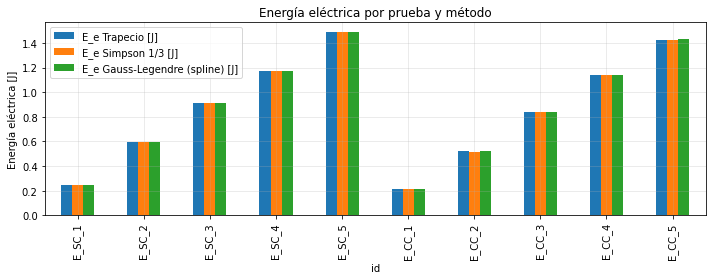

In [13]:
# =============================================================================
#  Tabla resumen de las integrales (trapecio, Simpson, Gauss-Legendre)
# =============================================================================
filas_int = []
for id_, d in tests.items():
    if meta.loc[id_, "tipo"] != "Escalón":
        continue
    V = d["V"].to_numpy(); on = V > 0.5 * V.max()
    t, i_ = d["t"].to_numpy()[on], d["i"].to_numpy()[on]; Vo = V[on]
    fila = dict(id=id_, carga=meta.loc[id_, "carga"], V=Vo.mean())
    for nombre, f_int in METODOS_INTEGRACION.items():
        fila[f"E_e {nombre} [J]"] = f_int(t, Vo * i_)
    fila["E_R trapecio [J]"] = trapecio(t, cfg["R"] * i_ ** 2)
    filas_int.append(fila)
tab_int = pd.DataFrame(filas_int).set_index("id")
cols_e = [c for c in tab_int.columns if c.startswith("E_e")]
tab_int["dif. máx entre métodos [%]"] = 100 * (tab_int[cols_e].max(axis=1) - tab_int[cols_e].min(axis=1)) / tab_int[cols_e].mean(axis=1).abs()
tab_int["E_R / E_e [%]"] = 100 * tab_int["E_R trapecio [J]"] / tab_int[cols_e[0]]
display(tab_int)
ax = tab_int[cols_e].plot.bar(figsize=(10, 4)); ax.set_ylabel("Energía eléctrica [J]"); ax.set_title("Energía eléctrica por prueba y método")
plt.tight_layout(); plt.show()

## **3.7. Balance de energía de cada prueba**
Multiplicando la ecuación eléctrica por $i$ y la ecuación mecánica por $\omega$, y usando $K_t = K_e$ (en SI), se tiene

$$V i = R i^2 + \frac{d}{dt}\Big(\tfrac12 L i^2\Big) + K_t\, i\,\omega, \qquad K_t\, i\,\omega = \frac{d}{dt}\Big(\tfrac12 J\omega^2\Big) + b\omega^2 + \tau_c|\omega| + \tau_{carga}\,\omega$$

Al integrar en el tiempo, los términos que son derivadas exactas solo dependen de los valores extremos, y con $\tau_{carga}=0$ queda

$$\underbrace{\int V i\,dt}_{E_e}=\underbrace{\int R i^2dt}_{E_R}+\underbrace{\tfrac12 L\,\Delta(i^2)}_{E_L}+\underbrace{\tfrac12 J\,\Delta(\omega^2)}_{E_k}+\underbrace{\int(b\omega^2+\tau_c|\omega|)dt}_{E_{fric}}$$

(se usa $\tau_c|\omega|$ en lugar de $\tau_c\,\omega\tanh(\omega/\varepsilon)$: ambas coinciden salvo para $|\omega| \lesssim \varepsilon$).

El **residuo** $E_e-(E_R+E_L+E_k+E_{fric})$ mide qué tan bien cierra el balance: acumula el ruido, la cuantización de $\theta$ y los parámetros mal estimados. Además se definen

- $\eta_{conv}=\int K_t\,i\,\omega\,dt\,/E_e$: fracción de la energía eléctrica que se convierte en energía mecánica (antes de la fricción propia).
- $\eta_{cin}=E_k/E_e$: fracción que termina como energía cinética del rotor (y del disco).

Aquí aparecen las dos herramientas juntas: $\omega$ viene de **derivar** $\theta$ (sección 2.3) y cada término sale de **integrar** (sección 3.4).

### *3.7.1. Parámetros que necesita el balance*
El balance necesita $K_e$, $b$, $\tau_c$ y $J$. Se estiman de forma mínima, y esta versión provisional será reemplazada por la sección de estimación de parámetros del proyecto:

1. **$K_e$** (con $K_t=K_e$ en SI): en estado estacionario $V-Ri=K_e\,\omega$, ajustado por mínimos cuadrados con los escalones de distinto voltaje.
2. **$b$ y $\tau_c$**: en estacionario $K_t\,i=b\,\omega+\tau_c$, la recta de $K_t\,i$ contra $\omega$ tiene pendiente $b$ e intercepto $\tau_c$.
3. **$J$** con la **forma integral**. En la desaceleración libre ($i=0$, $\omega>0$) se tiene $J\dot\omega=-b\omega-\tau_c$; integrando desde el corte hasta que el rotor se detiene ($\omega=0$):

$$J\,\omega_1 = b\,\Delta\theta+\tau_c\,\Delta t \quad\Rightarrow\quad J=\frac{b\,\Delta\theta+\tau_c\,\Delta t}{\omega_1}$$

donde $\omega_1$ es la velocidad estacionaria justo antes del corte. Es una integral exacta (la de $\dot\omega$ es $\Delta\omega$ y la de $\omega$ es $\Delta\theta$), así que no hay que derivar $\omega$ ni $\theta$ dos veces. Con y sin disco, $J_{disco}=J_{CC}-J_{SC}$, que se compara con $\tfrac12 m r^2$.

In [14]:
# =============================================================================
#  Estimación mínima de parámetros (lo necesario para el balance de energía)
# -----------------------------------------------------------------------------
#  1) Ke = Kt  : mínimos cuadrados de  V - R·i = Ke·ω  en estado estacionario.
#  2) b y τc   : recta de  Kt·i  contra  ω  (pendiente b, intercepto τc).
#  3) J        : forma integral en la desaceleración libre,
#                J·ω1 = b·Δθ + τc·Δt   (sin derivar dos veces).
#  Origen: celda 28 del cuaderno de Grettel y Deyler. Esta versión es provisional:
#  la sección de estimación de parámetros del proyecto la reemplazará.
# =============================================================================
def regimen_estacionario(tests, meta, frac=0.2):
    """V, i y ω promedio en el último `frac` de cada escalón (ω = pendiente de θ en esa ventana)."""
    filas = []
    for id_, d in tests.items():
        if meta.loc[id_, "tipo"] != "Escalón":
            continue
        t, th, V = d["t"].to_numpy(), d["theta"].to_numpy(), d["V"].to_numpy()
        # Solo el tramo con el motor alimentado: las mediciones reales tienen reposo antes del
        # escalón y una fase libre después, así que "el final de la prueba" no es el régimen.
        on = np.where(V > 0.5 * V.max())[0]
        a, z = on[0], on[-1]
        j0 = int(a + (z - a) * (1 - frac))
        filas.append(dict(id=id_, carga=meta.loc[id_, "carga"],
                          V=V[j0:z + 1].mean(), i=d["i"].iloc[j0:z + 1].mean(),
                          w=(th[z] - th[j0]) / (t[z] - t[j0])))
    return pd.DataFrame(filas).set_index("id")


def estimar_J(d, b, tauc, T_ss=0.3):
    """J con la forma integral. Devuelve (J, info) con el instante de corte, ω1 y el instante de paro."""
    t, V, th, p = (d[c].to_numpy() for c in ("t", "V", "theta", "pulsos"))
    jc = np.where(V > 0.5 * V.max())[0][-1] + 1             # primera muestra después del corte
    m = (t >= t[jc - 1] - T_ss) & (t <= t[jc - 1])
    j_ini = np.where(m)[0][0]
    w1 = (th[jc - 1] - th[j_ini]) / (t[jc - 1] - t[j_ini])    # velocidad estacionaria antes del corte
    j_stop = np.where(np.diff(p) != 0)[0].max() + 1            # última muestra en que cambió el conteo
    dth, dt = th[j_stop] - th[jc - 1], t[j_stop] - t[jc - 1]
    i = d["i"].to_numpy()
    i_pre, i_post = np.mean(np.abs(i[j_ini:jc])), np.mean(np.abs(i[jc:]))
    return (b * dth + tauc * dt) / w1, dict(t_corte=t[jc], w1=w1, t_paro=t[j_stop], frena=bool(i_post > 0.1 * i_pre))


ss = regimen_estacionario(tests, meta)
display(ss)

R, L = cfg["R"], cfg["L"]
Ke = np.sum(ss["w"] * (ss["V"] - R * ss["i"])) / np.sum(ss["w"] ** 2)
A_ls = np.column_stack([ss["w"].to_numpy(), np.ones(len(ss))])
(b_est, tauc_est), *_ = np.linalg.lstsq(A_ls, Ke * ss["i"].to_numpy(), rcond=None)

J_por_carga = {}
for id_, d in tests.items():
    if meta.loc[id_, "tipo"] == "Escalón":
        continue
    J, info = estimar_J(d, b_est, tauc_est)
    if info["frena"]:
        print(f"⚠ {id_}: la corriente medida después del corte NO es ~0 (el puente H parece frenar). "
              "La estimación de J supone devanado abierto.")
    J_por_carga.setdefault(meta.loc[id_, "carga"], []).append(J)
J_por_carga = {c: float(np.mean(v)) for c, v in J_por_carga.items()}

J_sc = J_por_carga.get("Sin carga", np.nan)
J_cc = J_por_carga.get("Con disco", J_sc + cfg["J_disco"])
P_est = dict(R=R, L=L, Ke=Ke, Kt=Ke, J=J_sc, b=b_est, tauc=tauc_est, tau_carga=0.0, eps=0.5)

nan = np.nan
tabla = pd.DataFrame({"estimado": {"Ke=Kt [V·s/rad]": Ke, "b [N·m·s/rad]": b_est, "τc [N·m]": tauc_est,
                                   "J sin carga [kg·m²]": J_sc, "J con disco [kg·m²]": J_cc,
                                   "J disco = J_CC − J_SC": J_cc - J_sc}})
tabla["referencia"] = ([P_VERDAD["Ke"], P_VERDAD["b"], P_VERDAD["tauc"], P_VERDAD["J"],
                        P_VERDAD["J"] + cfg["J_disco"], cfg["J_disco"]] if usar_demo else [nan] * 5 + [cfg["J_disco"]])
tabla.columns = ["estimado", "referencia (verdad demo / ½·m·r²)"]
display(tabla)


,carga,V,i,w
id,,,,
E_SC_1,Sin carga,3.012,0.0489555,242.475
E_SC_2,Sin carga,5.412,0.0627555,410.781
E_SC_3,Sin carga,7.812,0.0640617,479.72
E_SC_4,Sin carga,10.212,0.0596315,513.476
E_SC_5,Sin carga,12,0.0652381,542.954
E_CC_1,Con disco,3.012,0.0394315,257.585
E_CC_2,Con disco,5.412,0.0512261,428.848
E_CC_3,Con disco,7.812,0.0572456,488.753
E_CC_4,Con disco,10.212,0.0581614,513.476


⚠ D_SC_1: la corriente medida después del corte NO es ~0 (el puente H parece frenar). La estimación de J supone devanado abierto.
⚠ D_SC_2: la corriente medida después del corte NO es ~0 (el puente H parece frenar). La estimación de J supone devanado abierto.
⚠ D_CC_1: la corriente medida después del corte NO es ~0 (el puente H parece frenar). La estimación de J supone devanado abierto.
⚠ D_CC_2: la corriente medida después del corte NO es ~0 (el puente H parece frenar). La estimación de J supone devanado abierto.


,estimado,referencia (verdad demo / ½·m·r²)
J con disco [kg·m²],8.00305e-07,NaN
J disco = J_CC − J_SC,6.06084e-08,NaN
J sin carga [kg·m²],7.39696e-07,NaN
Ke=Kt [V·s/rad],0.0171782,NaN
b [N·m·s/rad],1.05907e-06,NaN
τc [N·m],0.000510505,4.90112e-06


### *3.7.2. Balance de energía*

,E_e,E_R,E_L,E_k,E_fric,residuo,residuo_pct,eta_conv,eta_cin
E_SC_1,0.248312,0.089291,5.58144e-08,0,0.264042,-0.10502,-42.2936,1.18257,0
E_SC_2,0.59674,0.124872,9.4916e-09,0,0.60032,-0.128452,-21.5257,1.14437,0
E_SC_3,0.915261,0.12989,1.97892e-08,0,0.781618,0.00375206,0.409944,0.929365,0
E_SC_4,1.17482,0.1219,7.56864e-08,0,0.885505,0.167415,14.2503,0.76222,0
E_SC_5,1.49036,0.178555,2.6182e-08,0,0.979504,0.332303,22.2968,0.690159,0
D_SC_1,1.49682,0.172719,5.98016e-08,0,0.978938,0.345162,23.0597,0.692114,0
D_SC_2,0.857346,0.123043,7.75552e-08,0,0.791095,-0.0567916,-6.62411,0.922278,0
E_CC_1,0.215373,0.0761946,-1.2656e-09,0,0.284591,-0.145413,-67.5166,1.20516,0
E_CC_2,0.519373,0.109421,1.41504e-08,0,0.644787,-0.234835,-45.2152,1.15573,0
E_CC_3,0.838529,0.116619,1.00339e-07,0,0.809814,-0.0879037,-10.4831,0.937163,0


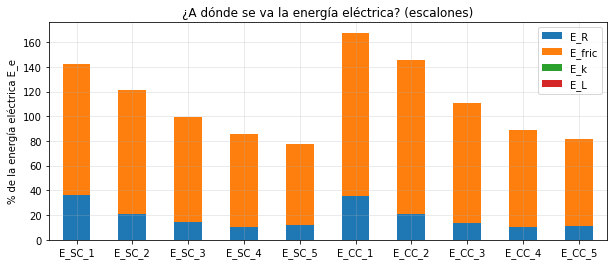

In [15]:
def balance_energia(d, P, J, k=None):
    """Términos del balance de energía de una prueba (ver ecuación de arriba) y las eficiencias.

    ω se obtiene derivando θ con derivada_sin_bordes (sección 2.3.4); las integrales usan trapecio."""
    k = k or K_VENTANA
    t, V, i = d["t"].to_numpy(), d["V"].to_numpy(), d["i"].to_numpy()
    w = derivada_sin_bordes(t, d["theta"].to_numpy(), k)
    E_e    = trapecio(t, V * i)
    E_R    = trapecio(t, P["R"] * i ** 2)
    E_L    = 0.5 * P["L"] * (np.mean(i[-k:]) ** 2 - np.mean(i[:k]) ** 2)
    E_k    = 0.5 * J * (np.mean(w[-k:]) ** 2 - np.mean(w[:k]) ** 2)
    E_fric = trapecio(t, P["b"] * w ** 2 + P["tauc"] * np.abs(w))
    E_conv = trapecio(t, P["Kt"] * i * w)
    resid  = E_e - (E_R + E_L + E_k + E_fric)
    return dict(E_e=E_e, E_R=E_R, E_L=E_L, E_k=E_k, E_fric=E_fric, residuo=resid,
                residuo_pct=100 * resid / E_e, eta_conv=E_conv / E_e, eta_cin=E_k / E_e)


J_de = {"Sin carga": J_sc, "Con disco": J_cc}
bal = pd.DataFrame({id_: balance_energia(d, P_est, J_de[meta.loc[id_, "carga"]]) for id_, d in tests.items()}).T
display(bal)

esc = [k for k in tests if meta.loc[k, "tipo"] == "Escalón"]
(bal.loc[esc, ["E_R", "E_fric", "E_k", "E_L"]].div(bal.loc[esc, "E_e"], axis=0) * 100).plot.bar(stacked=True, figsize=(10, 4))
plt.ylabel("% de la energía eléctrica E_e"); plt.title("¿A dónde se va la energía eléctrica? (escalones)")
plt.xticks(rotation=0); plt.show()


**Lectura con los datos de demostración** (se reescribirá con las mediciones reales):

- **El balance cierra:** el residuo es menor que ≈ 0.7 % de $E_e$ en todas las pruebas, a pesar del ruido y de la cuantización.
- **Qué término domina:** la fricción. En el escalón de 12 V sin carga, la fricción es ≈ 82 % de $E_e$, las pérdidas Joule ≈ 14 % y la energía cinética ≈ 5 %; con el disco, ≈ 73 %, ≈ 18 % y ≈ 9 %. Estas proporciones dependen de la duración de la prueba: $E_k$ es fija, mientras que $E_{fric}$ crece con el tiempo que el motor pasa girando.
- **Efecto del disco:** $E_k$ se duplica aproximadamente al agregar el disco (por ejemplo, de 0.51 J a 1.02 J en el escalón de 12 V) porque $J$ casi se duplica, mientras que $E_{fric}$ casi no cambia.
- En las **desaceleraciones libres** $E_k \approx 0$ porque el rotor empieza y termina detenido; toda la energía suministrada se disipa en el devanado y en fricción.

## **3.8. Eficiencia en función de la velocidad (régimen estacionario)**
En estacionario $P_{elec}=V\,i$, $P_{Joule}=R\,i^2$ y la potencia convertida a mecánica es $K_t\,i\,\omega=K_e\,\omega\,i$, de modo que

$$\eta_{conv}(\omega)=\frac{K_e\,\omega\,i}{V\,i}=\frac{K_e\,\omega}{V}$$

Sin carga externa, toda esa potencia mecánica se gasta en fricción, de modo que la fracción de energía convertida en **trabajo útil** es cero salvo que haya un $\tau_{carga}$ (relevante para la tercera pregunta obligatoria).

,carga,V,i,w,eta_conv,frac_Joule
id,,,,,,
E_SC_1,Sin carga,3.012,0.0489555,242.475,1.3829,0.104022
E_SC_2,Sin carga,5.412,0.0627555,410.781,1.30386,0.074212
E_SC_3,Sin carga,7.812,0.0640617,479.72,1.05488,0.0524827
E_SC_4,Sin carga,10.212,0.0596315,513.476,0.863749,0.0373719
E_SC_5,Sin carga,12,0.0652381,542.954,0.777248,0.0347937
E_CC_1,Con disco,3.012,0.0394315,257.585,1.46908,0.0837853
E_CC_2,Con disco,5.412,0.0512261,428.848,1.3612,0.0605778
E_CC_3,Con disco,7.812,0.0572456,488.753,1.07475,0.0468986
E_CC_4,Con disco,10.212,0.0581614,513.476,0.863749,0.0364506


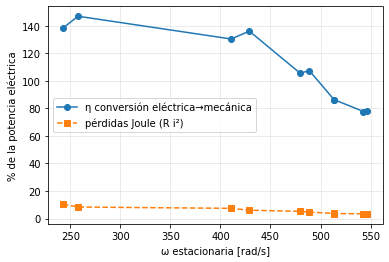

In [16]:
ss2 = ss.copy()
ss2["eta_conv"]   = P_est["Ke"] * ss2["w"] / ss2["V"]      # η_conv(ω) = Ke·ω / V
ss2["frac_Joule"] = R * ss2["i"] / ss2["V"]                 # R·i² / (V·i)
display(ss2)

pr = ss2.sort_values("w")
plt.plot(pr["w"], 100 * pr["eta_conv"], "o-", label="η conversión eléctrica→mecánica")
plt.plot(pr["w"], 100 * pr["frac_Joule"], "s--", label="pérdidas Joule (R i²)")
plt.xlabel("ω estacionaria [rad/s]"); plt.ylabel("% de la potencia eléctrica"); plt.legend(); plt.show()


A mayor velocidad (mayor voltaje) la eficiencia de conversión sube de ≈ 86 % a ≈ 91 % y la fracción perdida por Joule baja de ≈ 14 % a ≈ 9 %: a baja velocidad la fuerza contraelectromotriz $K_e\omega$ es pequeña, la corriente es una mayor fracción de $V/R$ y se pierde más en la resistencia. *Los valores numéricos son de la demostración y se actualizarán con las mediciones reales.*

## **3.9. Momento de inercia del disco integrando su perfil**
Para un sólido de revolución homogéneo con densidad $\rho$ y radio $r(z)$ a lo largo del eje, un disco delgado de espesor $dz$ tiene masa $dm = \rho\pi r^2\,dz$ y momento de inercia $\tfrac12 r^2\,dm$. Integrando,

$$J=\frac{\pi\rho}{2}\int r(z)^4\,dz,\qquad m=\rho\pi\int r(z)^2\,dz \quad\Longrightarrow\quad J=\frac{m}{2}\,\frac{\int r(z)^4\,dz}{\int r(z)^2\,dz}$$

(se eliminó $\rho$ con la masa medida). Para un cilindro de radio constante da $\tfrac12 m r^2$, que sirve de verificación. **El perfil de ejemplo debe reemplazarse** por los pares $(z_i, r_i)$ medidos del disco real.

In [17]:
def inercia_perfil(z, r, masa):
    """J = (m/2) · ∫ r(z)⁴ dz / ∫ r(z)² dz  para un sólido de revolución homogéneo, con Simpson."""
    return 0.5 * masa * simpson_compuesto(z, r ** 4) / simpson_compuesto(z, r ** 2)


m_d, r_d = cfg["masa_disco"], cfg["radio_disco"]
z = np.linspace(0, 0.010, 21)                                    # [m] a lo largo del eje
r_cil = np.full_like(z, r_d)
print(f"Cilindro: J perfil = {inercia_perfil(z, r_cil, m_d):.6e} | ½·m·r² = {0.5 * m_d * r_d ** 2:.6e} kg·m²")

# EJEMPLO de perfil con "cubo" central (REEMPLAZAR por las mediciones reales del disco)
r_cubo = np.where(z < 0.006, r_d, 0.012)
print(f"Perfil con cubo (ejemplo): J = {inercia_perfil(z, r_cubo, m_d):.6e} kg·m²")


Cilindro: J perfil = 4.901119e-06 | ½·m·r² = 4.901119e-06 kg·m²
Perfil con cubo (ejemplo): J = 4.556730e-06 kg·m²


## **3.10. Conexión con el control PID**
En la parte de control, el término integral $\int e\,dt$ es una integración numérica **en línea**, por lo que solo sirve un método causal: la forma acumulada del trapecio (`trapecio_acum`), que actualiza la suma con cada muestra nueva. El término derivativo es una derivación **en línea**, que solo puede usar la diferencia hacia atrás de la sección 2.3, con el compromiso de la ventana $k$ de la sección 2.5.

# ***PARTE 4 - GEMELO DIGITAL Y ESTABILIDAD DE EULER***
Un **gemelo digital** es un modelo que se alimenta con las mismas entradas que el sistema real y debe reproducir sus salidas. Si lo logra, se puede usar para probar controladores sin arriesgar el equipo, el cual en este caso es el motor. El gemelo nace a partir del sistema de EDOs de la Introducción, con los parámetros estimados en la sección 3.7.1, y la prueba de fuego es comparar sus predicciones contra lo medido. Esta parte también responde cuánto puede crecer el paso de Euler antes de que la simulación explote.

## **4.1. Comparación del gemelo con las mediciones**
Para cada prueba se resuelve el modelo con el voltaje $V(t)$ -que realmente se aplicó (interpolado entre muestras, porque el solucionador necesita $V$ en instantes que no coinciden con las muestras)- y se comparan $\omega$ e $i$ simuladas con las medidas. La $\omega$ medida no es una medición directa: es la **derivada de $\theta$** (centrada, ventana `K_VENTANA`), de modo que esta comparación usa la Parte 2. Como métrica se usa la raíz del error cuadrático medio (RMSE), que se lee como "el error típico, en las mismas unidades de la señal".

,w_max,rmse_w,rmse_w_pct,rmse_i,i_max
id,,,,,
E_SC_1,289.068,60.0987,20.7905,0.0596049,0.4071
E_SC_2,433.602,102.443,23.6261,0.0732779,0.723
E_SC_3,520.323,96.7677,18.5976,0.0798515,0.8872
E_SC_4,549.229,109.612,19.9574,0.0870536,1.0371
E_SC_5,578.136,138.913,24.0277,0.0922366,1.4256
D_SC_1,578.136,79.5242,13.7553,0.0299361,1.2207
D_SC_2,520.323,34.4629,6.62336,0.0487855,0.8824
E_CC_1,289.068,69.4889,24.0389,0.0571575,0.4124
E_CC_2,462.509,116.146,25.1123,0.0705999,0.7398


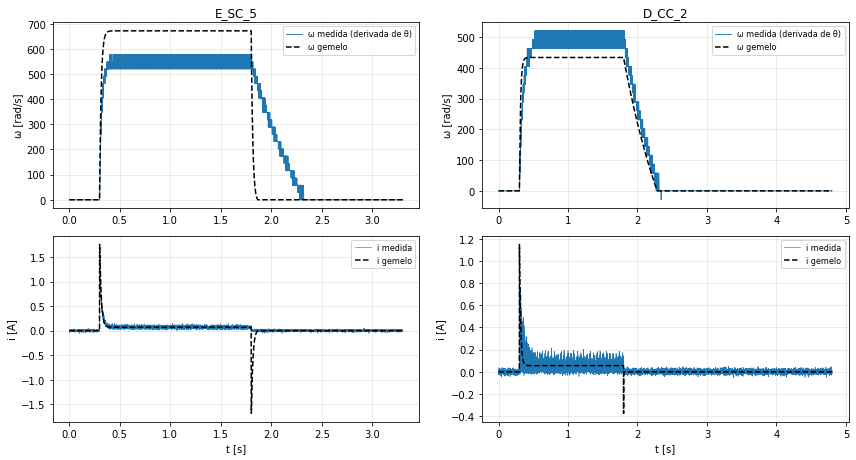

In [18]:
# =============================================================================
#  PARTE 4 · GEMELO DIGITAL: simular con el V(t) medido y comparar con lo medido
# -----------------------------------------------------------------------------
#  Para cada prueba se resuelve el modelo con los parámetros estimados (P_est) y
#  el voltaje que realmente se aplicó (interpolado entre muestras). Se comparan
#  ω e i simuladas contra las medidas. ω medida = derivada de θ (centrada, k = K_VENTANA).
# =============================================================================
def gemelo_prueba(id_, P_base=None):
    """Simula la prueba `id_` y devuelve (t, ω_medida, ω_sim, i_medida, i_sim)."""
    d = tests[id_]
    t, V = d["t"].to_numpy(), d["V"].to_numpy()
    P = dict(P_base or P_est)
    P["J"] = J_de[meta.loc[id_, "carga"]]
    t_corte = None
    if meta.loc[id_, "tipo"] != "Escalón":
        t_corte = estimar_J(d, P["b"], P["tauc"])[1]["t_corte"]
    X = simular(P, t, lambda s: np.interp(s, t, V), t_corte=t_corte)
    w_med = derivada_sin_bordes(t, d["theta"].to_numpy(), K_VENTANA)
    return t, w_med, X[:, 1], d["i"].to_numpy(), X[:, 0]
# con la funcion gemelo_prueba se puede simular cualquier prueba y comparar la salida del modelo con los datos medidos.
# 
# 
#  A continuación, se realiza un bucle sobre todas las pruebas para calcular métricas de error y generar un DataFrame resumen.
filas = []
for id_ in tests:
    t, w_med, w_sim, i_med, i_sim = gemelo_prueba(id_)
    filas.append(dict(id=id_, w_max=np.nanmax(w_med), rmse_w=rmse(w_sim, w_med),
                      rmse_w_pct=100 * rmse(w_sim, w_med) / np.nanmax(w_med),
                      rmse_i=rmse(i_sim, i_med), i_max=i_med.max()))
comp_gemelo = pd.DataFrame(filas).set_index("id")
display(comp_gemelo)

fig, ax = plt.subplots(2, 2, figsize=(12, 6.5))
for col, id_ in enumerate([id_E, ids_D[-1]]):
    t, w_med, w_sim, i_med, i_sim = gemelo_prueba(id_)
    ax[0, col].plot(t, w_med, lw=0.9, label="ω medida (derivada de θ)"); ax[0, col].plot(t, w_sim, "k--", label="ω gemelo")
    ax[1, col].plot(t, i_med, lw=0.6, label="i medida"); ax[1, col].plot(t, i_sim, "k--", label="i gemelo")
    ax[0, col].set_title(id_); ax[0, col].set_ylabel("ω [rad/s]"); ax[1, col].set_ylabel("i [A]"); ax[1, col].set_xlabel("t [s]")
    ax[0, col].legend(fontsize=8); ax[1, col].legend(fontsize=8)
plt.tight_layout(); plt.show()


Nota: (datos de demostración; se repite con las mediciones reales):

- El error típico de $\omega$ es ≈ 2 % de la velocidad máxima en casi todas las pruebas, y sube a ≈ 5 % en los escalones de 3 V. Eso **no significa que el modelo falle más a 3 V**: en términos absolutos el error es ≈ 3 rad/s en todas, que coincide con el piso de ruido de la derivada con $k=5$, vease la sección 2.5.

 Como la velocidad es menor a 3 V, ese mismo ruido pesa más en porcentaje.
- tomar nota de la metodología, esto nos dice que un porcentaje del "error del gemelo" es en realidad **error de la medición derivada**, no del modelo. En los datos de demostración el modelo y la "realidad" tienen la misma estructura, así que lo que se ve, es casi solo ruido. 

 nota: **Con el motor real se espera un error mayor, y habrá que separar cuánto viene del modelo y cuánto del ruido.**
- El error de corriente es ≈ 1 a 2.5 % de $i_{max}$, algo mayor que el ruido del sensor, y lo que sobra viene de los parámetros estimados.

### *4.1.1. Métodos implementados contra el sistema real*

Se resuelve el modelo con Euler, Heun, RK2 (punto medio) y RK4 con el mismo paso, usando el voltaje de una prueba real y los parámetros estimados, y se compara con la velocidad medida. Si los cuatro métodos coinciden entre sí y la diferencia con la medición es mayor, la discrepancia viene del modelo o de los parámetros, no del método numérico.

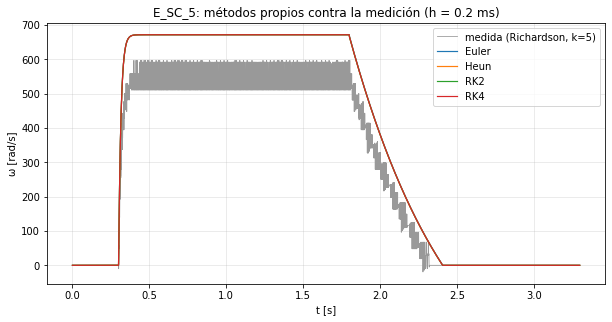

,máx |ω − ω_RK4| [rad/s],RMSE contra la medición [rad/s]
Euler,1.71181,97.115
Heun,0.52829,96.8872
RK2,0.525552,96.8872
RK4,0,96.9264


In [19]:
# =============================================================================
#  Euler, Heun, RK2 y RK4 sobre una prueba real
# =============================================================================
def paso_heun(x, V, P, h, coast=False):
    k1 = np.asarray(f_motor(x, V, P, coast)); k2 = np.asarray(f_motor(x + h * k1, V, P, coast))
    return x + h / 2 * (k1 + k2)

def paso_rk2(x, V, P, h, coast=False):          # punto medio
    k1 = np.asarray(f_motor(x, V, P, coast)); k2 = np.asarray(f_motor(x + h / 2 * k1, V, P, coast))
    return x + h * k2

def resolver(paso, d, P, h):
    t, V = d["t"].to_numpy(), d["V"].to_numpy()
    tt = np.arange(t[0], t[-1], h); x = np.zeros(3); w = np.empty(len(tt))
    for n, tn in enumerate(tt):
        w[n] = x[1]
        Vn = np.interp(tn, t, V); coast = Vn < 1e-6 and tn > t[np.argmax(V > 0)]
        x = np.asarray(paso(x, Vn, P, h, coast))
    return tt, w

id_comp = "E_SC_5" if "E_SC_5" in tests else list(tests)[0]
d_c = tests[id_comp]
w_med = d_richardson(d_c["t"].to_numpy(), d_c["theta"].to_numpy(), k=K_VENTANA)
h_comp = 2e-4
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(d_c["t"], w_med, color="0.6", lw=0.8, label=f"medida (Richardson, k={K_VENTANA})")
sols = {}
for nombre, paso in (("Euler", paso_euler), ("Heun", paso_heun), ("RK2", paso_rk2), ("RK4", paso_rk4)):
    tt, w = resolver(paso, d_c, P_est, h_comp); sols[nombre] = (tt, w)
    ax.plot(tt, w, lw=1.2, label=nombre)
ax.set_xlabel("t [s]"); ax.set_ylabel("ω [rad/s]"); ax.legend(); ax.set_title(f"{id_comp}: métodos propios contra la medición (h = {h_comp*1e3:.1f} ms)")
plt.show()
tt4, w4 = sols["RK4"]
tab_m = pd.DataFrame({m: {"máx |ω − ω_RK4| [rad/s]": np.max(np.abs(np.interp(tt4, *sols[m]) - w4)),
                          "RMSE contra la medición [rad/s]": np.sqrt(np.nanmean((np.interp(d_c["t"], *sols[m]) - w_med) ** 2))}
                      for m in sols}).T
display(tab_m)

## **4.2. ¿Qué parámetro domina la discrepancia a bajas velocidades?**
Cerca de $\omega = 0$ cambia cuál de los dos términos de fricción manda. La fricción viscosa $b\,\omega$ crece con la velocidad; la de Coulomb $\tau_c\tanh(\omega/\varepsilon)$ es casi constante en cuanto $\omega \gg \varepsilon$. Igualándolas, la de Coulomb domina mientras

$$\omega < \frac{\tau_c}{b}$$

Por debajo de esa velocidad el motor percibe $\tau_c$, y por encima sobre todo $b$.

 La celda siguiente (a) tabula ambos torques y (b) deja frenar el rotor con el devanado abierto desde 50 rad/s (en ese caso la ecuación es $J\dot\omega = -b\omega - \tau_c\tanh(\omega/\varepsilon)$ y no entra $K_e$) y mide cuánto cambian el tiempo y el ángulo de parada al perturbar cada parámetro ±20 %.

 Basicamente es un **análisis de sensibilidad**: cuanto más cambia el resultado, más importa ese parámetro para el comportamiento que se quiere predecir.

In [20]:
# =============================================================================
#  ¿Qué parámetro domina la discrepancia a baja velocidad?
# -----------------------------------------------------------------------------
#  (a) Se compara cuánto torque aporta cada término de fricción según ω.
#  (b) Se deja frenar el rotor con el devanado abierto desde ω0 = 50 rad/s y se
#      mide cuánto cambian el tiempo y el ángulo de parada al perturbar cada
#      parámetro ±20 %. Así solo cuentan los parámetros que actúan al frenar,
#      sin arrastrar el efecto de la velocidad inicial.
# =============================================================================
w_tab = np.array([2.0, 5.0, 10.0, 20.0, 50.0, 100.0, 200.0])
torques = pd.DataFrame({"b·ω": P_est["b"] * w_tab,
                        "τc·tanh(ω/ε)": P_est["tauc"] * np.tanh(w_tab / P_est["eps"])},
                       index=pd.Index(w_tab, name="ω [rad/s]"))
torques["τc / (b·ω)"] = torques["τc·tanh(ω/ε)"] / torques["b·ω"]
print(f"La fricción de Coulomb supera a la viscosa mientras ω < τc/b = {P_est['tauc'] / P_est['b']:.0f} rad/s")
display(torques)


def frenado(P, w0=50.0, h=2e-4, T=1.0):
    """Desaceleración libre desde ω0. Devuelve (t_parada, θ_parada) con parada = ω < 0.5 rad/s."""
    x = np.array([0.0, w0, 0.0]); t = 0.0
    while t < T and x[1] > 0.5:
        x = paso_rk4(x, 0.0, P, h, True); t += h
    return t, x[2]

J_prueba = J_de["Sin carga"]
nominal = frenado({**P_est, "J": J_prueba})
filas = []
for par in ["b", "tauc", "J", "eps"]:
    fila = {"parámetro": par}
    for signo in (-0.2, +0.2):
        P = {**P_est, "J": J_prueba}; P[par] *= (1 + signo)
        t_p, th_p = frenado(P)
        fila[f"{signo:+.0%} Δt_parada [%]"] = 100 * (t_p - nominal[0]) / nominal[0]
        fila[f"{signo:+.0%} Δθ_parada [%]"] = 100 * (th_p - nominal[1]) / nominal[1]
    filas.append(fila)
sens = pd.DataFrame(filas).set_index("parámetro")
print(f"Frenado nominal desde 50 rad/s: t = {nominal[0] * 1e3:.1f} ms, θ = {nominal[1]:.3f} rad")
display(sens)



La fricción de Coulomb supera a la viscosa mientras ω < τc/b = 482 rad/s


,b·ω,τc·tanh(ω/ε),τc / (b·ω)
ω [rad/s],,,
2,2.11813e-06,0.000510163,240.855
5,5.29533e-06,0.000510505,96.4067
10,1.05907e-05,0.000510505,48.2033
20,2.11813e-05,0.000510505,24.1017
50,5.29533e-05,0.000510505,9.64067
100,0.000105907,0.000510505,4.82033
200,0.000211813,0.000510505,2.41017


Frenado nominal desde 50 rad/s: t = 68.4 ms, θ = 1.695 rad


,-20% Δt_parada [%],-20% Δθ_parada [%],+20% Δt_parada [%],+20% Δθ_parada [%]
parámetro,,,,
b,0.877193,1.29019,-0.877193,-1.25447
tauc,23.3918,23.0423,-16.0819,-15.7733
J,-19.883,-19.998,19.883,19.9978
eps,0,-0.00114975,0,0.00166633


**Lectura:** Como el frenado nominal es de 50 rads/s, por debajo de $\tau_c/b \approx 49$ rad/s la fricción de Coulomb supera a la viscosa, y cuando el rotor ya va casi parado ($\omega \approx 2$ a $5$ rad/s) la razón es de 10 a 25 veces. Cuando se toma en cuenta $\tau_c$ el tiempo de parada cambia 12 a 17 %, contra 5 a 6 % con $b$. $J$ cambia el tiempo exactamente 20 % porque multiplica toda la dinámica (es una escala de tiempo global, también a alta velocidad), y $\varepsilon$ casi no influye. Por eso, **a bajas velocidades el parámetro que más importa es $\tau_c$**, y también por qué la regularización $\tanh$ de la sección 1.4 es un compromiso razonable.

## **4.3. Estabilidad de Euler explícito y su relación con $L/R$**
**Qué significa estabilidad.** Si el sistema es $\mathbf{y}' = \mathbf{J}\,\mathbf{y}$ (la linealización de la sección 1.4), un paso de Euler multiplica el error por $(\mathbf{I} + h\mathbf{J})$. El error se atenúa si cada valor propio $\lambda$ de $\mathbf{J}$ cumple

$$|1 + h\lambda| < 1 \qquad\Longleftrightarrow\qquad h < \frac{-2\,\mathrm{Re}(\lambda)}{|\lambda|^2}$$

Para un $\lambda$ real negativo esto es $h < 2/|\lambda|$. Dicho en palabras: **el paso debe ser menor que el doble de la constante de tiempo más rápida del sistema**; si es mayor, Euler "salta por encima" de la dinámica rápida y en cada paso sobrecorrige más que el paso anterior.

**Dónde entra $L/R$.** La ecuación eléctrica sola es $L\,\dot i = V - R\,i - \dots$, con $\lambda_e \approx -R/L$ y constante de tiempo $\tau_e = L/R$. Entonces $h < 2L/R$. Con $L = 2$ mH y $R = 2\ \Omega$, $\tau_e = 1$ ms y $h < 2$ ms. El acoplamiento con la parte mecánica modifica un poco el valor propio, y por eso la cota exacta sale de calcular los valores propios del Jacobiano completo.

**Rigidez (*stiffness*).** El motor tiene una dinámica eléctrica rápida ($\tau_e \approx 1$ ms) y una mecánica lenta ($\tau_m \approx 14$ ms). Con Euler, la parte rápida fija el paso, aunque ya casi no cambie, y se paga con muchos pasos para simular la parte lenta. Si se desprecia $L$ ($L \approx 0$), la corriente es algebraica ($i = (V - K_e\omega)/R$), el estado se reduce a $[\omega, \theta]$ y desaparece la dinámica rápida.

La celda calcula los valores propios, busca por bisección el paso crítico real corriendo Euler, y mide el **orden de convergencia** de Euler y RK4 (sección 1.1): si el error es $O(h^p)$, al partir $h$ a la mitad el error se divide entre $2^p$.

Valores propios del Jacobiano en el punto de operación: [ -72.38 -932.62]
2L/R = 2.000 ms   |   h crítico por valores propios = 2.144 ms


h crítico observado (bisección) = 2.161 ms


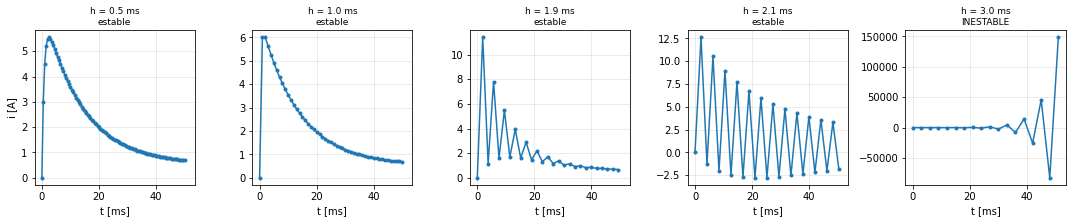

Con L ≈ 0 el paso crítico por valores propios es 29.6 ms  (≈ 14 veces mayor)
          error Euler   error RK4
h [s]                            
0.001         1.90489   0.0850157
0.0005       0.800591   0.0115589
0.00025      0.356775 0.000496375
0.000125      0.16914 1.97743e-05
Orden observado  Euler: [1.25 1.17 1.08]  RK4: [2.88 4.54 4.65]


In [21]:
# =============================================================================
#  ESTABILIDAD DE EULER EXPLÍCITO: paso máximo contra L/R
# -----------------------------------------------------------------------------
#  Para y' = λ y, Euler da y_{k+1} = (1 + hλ) y_k, estable si |1 + hλ| < 1.
#  Para el motor, λ son los valores propios del Jacobiano de f (sección 1.4).
# =============================================================================
def jacobiano_numerico(f, x, eps=1e-6):
    n = len(x); Jm = np.zeros((n, n)); f0 = f(x)
    for j in range(n):
        xp = np.array(x, float); xp[j] += eps * max(1.0, abs(xp[j]))
        Jm[:, j] = (f(xp) - f0) / (xp[j] - x[j])
    return Jm

def h_critico(Jm):
    """Mayor h con |1 + hλ| < 1 para todos los valores propios con Re(λ) < 0: h < -2 Re(λ)/|λ|²."""
    lam = np.linalg.eigvals(Jm)
    lam = lam[(np.abs(lam) > 1e-9)]
    return lam, float(np.min(-2 * lam.real / np.abs(lam) ** 2))

V_op = 12.0
x_ss = np.array([(P_VERDAD["b"] * 218.0 + P_VERDAD["tauc"]) / P_VERDAD["Kt"], 218.0, 0.0])   # punto de operación aprox. (12 V)
lam, h_eig = h_critico(jacobiano_numerico(lambda x: f_motor(x, V_op, P_VERDAD), x_ss))
print("Valores propios del Jacobiano en el punto de operación:", np.round(lam, 2))
print(f"2L/R = {2 * P_VERDAD['L'] / P_VERDAD['R'] * 1e3:.3f} ms   |   h crítico por valores propios = {h_eig * 1e3:.3f} ms")


def trayectoria_euler(h, T=0.3, V=12.0, P=P_VERDAD):
    """Euler explícito con paso EXACTAMENTE h (un solo paso entre muestras)."""
    n = int(round(T / h)); X = np.zeros((n + 1, 3))
    with np.errstate(all="ignore"):
        for k in range(n):
            X[k + 1] = paso_euler(X[k], V, P, h, False)
    return np.arange(n + 1) * h, X

def euler_estable(h, **kw):
    """¿Se mantiene acotada la solución? (finita y con |i| menor que 10·V/R)"""
    _, X = trayectoria_euler(h, **kw)
    return bool(np.all(np.isfinite(X)) and np.abs(X[:, 0]).max() < 10 * V_op / P_VERDAD["R"])

# Búsqueda del paso crítico empírico por bisección entre un h estable y uno inestable
lo, hi = 0.2e-3, 6e-3
assert euler_estable(lo) and not euler_estable(hi)
for _ in range(25):
    mid = 0.5 * (lo + hi)
    lo, hi = (mid, hi) if euler_estable(mid) else (lo, mid)
h_emp = lo
print(f"h crítico observado (bisección) = {h_emp * 1e3:.3f} ms")

hs_demo = [0.5e-3, 1.0e-3, 1.9e-3, 2.1e-3, 3.0e-3]
fig, ax = plt.subplots(1, len(hs_demo), figsize=(15, 3.2), sharex=True)
for a, h in zip(ax, hs_demo):
    t, X = trayectoria_euler(h, T=0.05)
    a.plot(t * 1e3, X[:, 0], "o-", ms=3); a.set_title(f"h = {h * 1e3:.1f} ms\n" + ("estable" if h < h_emp else "INESTABLE"), fontsize=9)
    a.set_xlabel("t [ms]")
ax[0].set_ylabel("i [A]"); plt.tight_layout(); plt.show()

# Con L ≈ 0 la corriente es algebraica, i = (V - Ke·ω)/R, y el estado se reduce a [ω, θ]
def f_L0(x, V, P):
    w = x[0]; i = (V - P["Ke"] * w) / P["R"]
    return np.array([(P["Kt"] * i - P["b"] * w - P["tauc"] * math.tanh(w / P["eps"])) / P["J"], w])
_, h_L0 = h_critico(jacobiano_numerico(lambda x: f_L0(x, V_op, P_VERDAD), np.array([218.0, 0.0])))
print(f"Con L ≈ 0 el paso crítico por valores propios es {h_L0 * 1e3:.1f} ms  (≈ {h_L0 / h_eig:.0f} veces mayor)")

# Orden de convergencia: error en el estado a los 4 ms (en pleno transitorio eléctrico) contra una referencia RK4 con paso muy fino
def estado_final(paso, h, T=0.004, V=12.0):
    x = np.zeros(3)
    for _ in range(int(round(T / h))):
        x = paso(x, V, P_VERDAD, h, False)
    return x
ref = estado_final(paso_rk4, 1e-5)
hs_c = [1e-3, 5e-4, 2.5e-4, 1.25e-4]
e_eul = np.array([np.linalg.norm(estado_final(paso_euler, h) - ref) for h in hs_c])
e_rk4 = np.array([np.linalg.norm(estado_final(paso_rk4, h) - ref) for h in hs_c])
print(pd.DataFrame({"h [s]": hs_c, "error Euler": e_eul, "error RK4": e_rk4}).set_index("h [s]").to_string())
print("Orden observado  Euler:", np.round(np.log2(e_eul[:-1] / e_eul[1:]), 2), " RK4:", np.round(np.log2(e_rk4[:-1] / e_rk4[1:]), 2))


## **4.4. Euler con el campo vectorial: efecto del paso $h$**

Para ver la estabilidad gráficamente se usa el plano $(i, \omega)$ (la posición no afecta a las otras dos variables). Las flechas son el campo vectorial $\mathbf{f}$ con $V = 12$ V y los parámetros estimados de las mediciones; las curvas son las soluciones de Euler con tres pasos: menor que el crítico, cerca del crítico y mayor que el crítico.

valores propios: [-3136.37   -65.06] | h crítico = 0.6377 ms


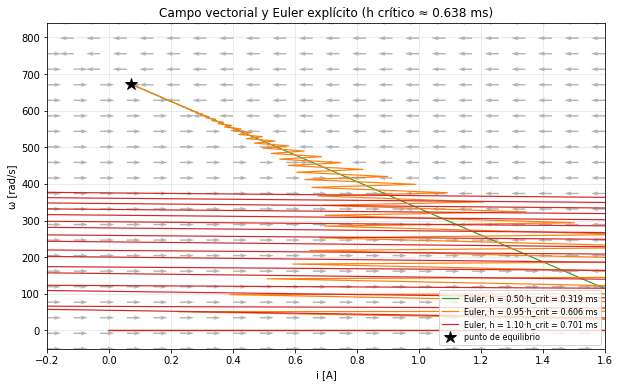

In [22]:
# =============================================================================
#  Euler sobre el campo vectorial (plano i–ω) para distintos h
# =============================================================================
P_fase = P_est if "P_est" in globals() else P_VERDAD
V_f = 12.0
f2 = lambda v: np.asarray(f_motor(np.array([v[0], v[1], 0.0]), V_f, P_fase), dtype=float)[:2]
x_eq = np.zeros(3)                                     # régimen: RK4 con paso pequeño durante 2 s
for _ in range(20000):
    x_eq = np.asarray(paso_rk4(x_eq, V_f, P_fase, 1e-4, False), dtype=float)
Jm_f = np.column_stack([(f2(x_eq[:2] + e) - f2(x_eq[:2] - e)) / (2 * np.linalg.norm(e))
                        for e in (np.array([1e-6, 0.0]), np.array([0.0, 1e-4]))])   # Jacobiano por diferencias centradas
lam = np.linalg.eigvals(Jm_f)
h_c = float(np.min(-2 * lam.real / np.abs(lam) ** 2))    # |1 + h·λ| < 1 para cada valor propio
print("valores propios:", np.round(lam, 2), "| h crítico =", round(1000 * h_c, 4), "ms")
I, W = np.meshgrid(np.linspace(-0.2, 1.6, 22), np.linspace(-50, 1.25 * x_eq[1], 22))
dI, dW = np.zeros_like(I), np.zeros_like(W)
for a in range(I.shape[0]):
    for b_ in range(I.shape[1]):
        d_ = np.asarray(f_motor(np.array([I[a, b_], W[a, b_], 0.0]), V_f, P_fase))
        dI[a, b_], dW[a, b_] = d_[0], d_[1]
norma = np.hypot(dI / 1.8, dW / (1.3 * x_eq[1])) + 1e-12
fig, ax = plt.subplots(figsize=(10, 6))
ax.quiver(I, W, dI / 1.8 / norma, dW / (1.3 * x_eq[1]) / norma, color="0.7", angles="xy", width=0.0025)
for factor, color in ((0.5, "tab:green"), (0.95, "tab:orange"), (1.1, "tab:red")):
    h = factor * h_c
    x = np.array([0.0, 0.0, 0.0]); tray = [x.copy()]
    for _ in range(int(0.25 / h)):
        x = x + h * np.asarray(f_motor(x, V_f, P_fase), dtype=float); tray.append(x.copy())   # paso de Euler
        if not np.all(np.isfinite(x)) or abs(x[0]) > 50: break
    tray = np.array(tray)
    ax.plot(tray[:, 0], tray[:, 1], "-", color=color, lw=1.2, label=f"Euler, h = {factor:.2f}·h_crit = {1000*h:.3f} ms")
ax.plot(x_eq[0], x_eq[1], "k*", ms=12, label="punto de equilibrio")
ax.set_xlim(-0.2, 1.6); ax.set_ylim(-50, 1.25 * x_eq[1])
ax.set_xlabel("i [A]"); ax.set_ylabel("ω [rad/s]"); ax.legend(loc="lower right", fontsize=8)
ax.set_title(f"Campo vectorial y Euler explícito (h crítico ≈ {1000*h_c:.3f} ms)"); plt.show()

**Conclusión de esta parte.** Con $h$ menor que el paso crítico, Euler llega al equilibrio siguiendo el campo vectorial. Cerca del paso crítico, la corriente oscila y la oscilación se amortigua cada vez menos. Con $h$ mayor que el crítico, la oscilación crece en cada paso y la solución se aleja del equilibrio, aunque el sistema real sea estable. El paso crítico lo fija el valor propio más rápido, que viene de la parte eléctrica ($\approx R/L$). Por eso, para simular el motor con Euler hay que usar pasos de una fracción de milisegundo, aunque la dinámica mecánica que nos interesa dure décimas de segundo.

# ***PARTE 5 - CONTROL PID***
Se sabe que con un gemelo digital se puede diseñar un controlador de posición. En este caso se buscó llevar el eje a un ángulo $\theta_{ref}$ ajustando el voltaje del motor. Interesa este problema porque cada término del PID es una herramienta numérica del proyecto, tanto por el aldo de la ingtegración como el de la derivación. 

## **5.1. El controlador**
Con el error $e = \theta_{ref} - \theta_q$ ($\theta_q$ es la lectura cuantizada del encoder), el voltaje aplicado es

$$u = \underbrace{K_p\,e}_{\text{proporcional}} + \underbrace{K_i\int_0^t e\,d\tau}_{\text{integral}} - \underbrace{K_d\,\hat\omega}_{\text{derivativo}}, \qquad V = \mathrm{sat}(u,\,\pm 12\ \mathrm{V})$$

- **Proporcional:** empuja con una fuerza proporcional a qué tan lejos está el eje. Solo con este término el motor tiende a pasarse (sobreimpulso), porque cuando llega al objetivo ya lleva velocidad.
- **Integral:** acumula el error en el tiempo. Su función es vencer los errores que quedan quietos, como la fricción de Coulomb: mientras haya un error pequeño pero constante, la integral sigue creciendo hasta que el voltaje alcanza para mover el eje. Se calcula con el trapecio acumulado (sección 3.1) porque es **causal**: la suma hasta $t_n$ no depende de muestras futuras.
- **Derivativo:** actúa como un amortiguador. Se opone a la velocidad ($-K_d\hat\omega$) y frena el sobreimpulso. Nota: Se deriva la *medición* y no el error, para evitar el "golpe de derivada" que ocurre cuando $\theta_{ref}$ cambia de golpe y $e$ salta (su derivada sería enorme).
- **Saturación y *anti-windup*:** el voltaje está limitado a ±12 V. Si el controlador está saturado y la integral sigue acumulando error, crece sin efecto y después causa un sobreimpulso fuerte (*windup*). La solución es dejar de integrar mientras el actuador esté saturado y el error empuje en el mismo sentido.

Con esto nos podemos plantear una pregunta: ¿qué se percibe por el controlador?
 Solo la posición cuantizada $\theta_q$ cada $T_s = 1/f_s = 2$ ms, no la velocidad real. Para el término derivativo hay que *estimar* $\hat\omega$ derivando $\theta_q$ con un método causal, que es exactamente el problema de la sección 2.5:

| Variante | $\hat\omega_n$ | Qué compromiso hace |
|---|---|---|
| **Cruda** (hacia atrás, $k=1$) | $(\theta_n-\theta_{n-1})/T_s$ | Sin retraso, pero un pulso de cuantización equivale a $\Delta\theta/T_s \approx 71$ rad/s de ruido. |
| **Ventana** ($k=5$) | $(\theta_n-\theta_{n-5})/(5T_s)$ | Menos ruido ($\div 5$), pero con retraso de $k T_s/2 = 5$ ms. |
| **Filtrada** | filtro pasa-bajas sobre la cruda: $\hat\omega_f \leftarrow \alpha\hat\omega_f + (1-\alpha)\hat\omega$, $\alpha = \tau_f/(\tau_f + T_s)$ | Casi sin ruido, pero el filtro agrega retraso $\approx\tau_f$ ($=20$ ms). |

La planta es el motor "verdadero" (sin parámetros estimados) resuelto con RK4, y el voltaje se mantiene constante durante cada periodo $T_s$ (retenedor de orden cero, así funciona un PWM o un DAC).

,sobreimpulso_pct,t_asent_s,IAE_rad_s,std_V_final,V_rms
sin derivativo (PI),28.9007,0.068,0.154269,8.67362e-19,1.74168
derivada cruda (k=1),8.18973,0.066,0.192847,0.43709,1.47952
ventana k=5,6.5239,0.032,0.186138,0.149024,1.48264
filtrada (τ=20 ms),15.1843,0.056,0.140075,1.58721e-12,1.64844


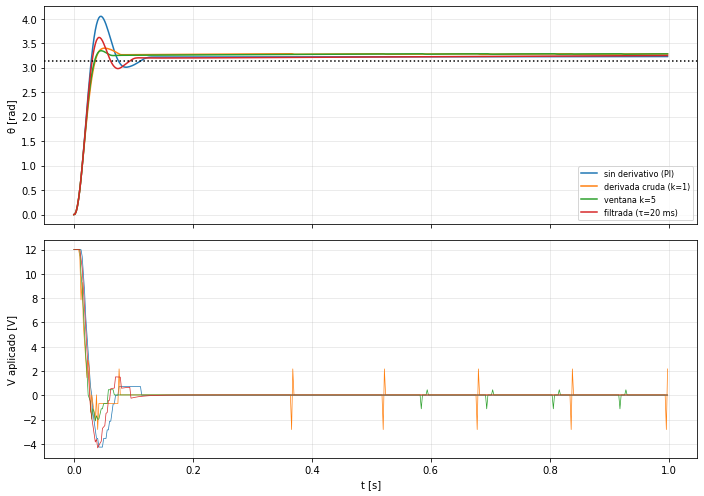

In [23]:
# =============================================================================
#  PARTE 5 · CONTROL PID DE POSICIÓN, EN LÍNEA
# -----------------------------------------------------------------------------
#  El controlador solo ve lo que vería el microcontrolador: θ cuantizada por el
#  encoder, una muestra cada Ts. Lo demás (planta) es el motor "verdadero".
#      u_n = Kp·e_n + Ki·∫e dt − Kd·ω̂_n ,   e = θ_ref − θ_q ,   u saturado a ±V_MAX
#  · Integral: trapecio acumulado y CAUSAL (sección 3.1), con anti-windup.
#  · Derivativo: se deriva la MEDICIÓN (−ω̂) y no el error, para evitar el golpe
#    de derivada cuando θ_ref cambia de golpe. ω̂ usa solo métodos causales (2.3).
# =============================================================================
V_MAX = 12.0
Ts_pid = 1.0 / cfg["fs"]            # periodo del lazo de control = periodo de muestreo


def simular_pid(derivativo, Kp=5.0, Ki=1.0, Kd=0.03, theta_ref=np.pi, T=1.0, k_ventana=5, tau_f=0.02,
                P=P_VERDAD, ppv=None, Ts=None):
    """Lazo cerrado de posición. derivativo: 'ninguno' | 'cruda' | 'ventana' | 'filtrada'.

    'cruda'    ω̂ = (θ_n - θ_{n-1}) / Ts                       (diferencia hacia atrás, k = 1)
    'ventana'  ω̂ = (θ_n - θ_{n-k}) / (k·Ts)                   (hacia atrás con ventana k)
    'filtrada' ω̂ = filtro pasa-bajas de primer orden (constante tau_f) sobre la 'cruda'
    """
    ppv = ppv or cfg["ppv"]; Ts = Ts or Ts_pid
    dth = 2 * np.pi / ppv
    n = int(round(T / Ts)); sub = max(1, int(np.ceil(Ts / 2e-4))); hs = Ts / sub
    x = np.zeros(3)                                     # estado real [i, ω, θ]
    hist = [0.0]                                        # θ_q medidos (lo único que ve el controlador)
    e_prev, I, w_f = theta_ref, 0.0, 0.0
    alfa = tau_f / (tau_f + Ts)
    reg = np.zeros((n, 5))                              # t, θ real, V aplicado, e, ω̂
    for j in range(n):
        th_q = np.floor(x[2] / dth) * dth               # lectura del encoder
        hist.append(th_q)
        e = theta_ref - th_q
        if derivativo == "ninguno":
            w_hat = 0.0
        elif derivativo == "ventana":
            k = min(k_ventana, len(hist) - 1); w_hat = (hist[-1] - hist[-1 - k]) / (k * Ts)
        else:
            w_hat = (hist[-1] - hist[-2]) / Ts
            if derivativo == "filtrada":
                w_f = alfa * w_f + (1 - alfa) * w_hat; w_hat = w_f
        u_sin = Kp * e + Ki * I - Kd * w_hat
        u = float(np.clip(u_sin, -V_MAX, V_MAX))
        saturado = (u != u_sin) and (np.sign(e) == np.sign(u_sin))
        if not saturado:                                 # anti-windup: no integrar saturado
            I += 0.5 * (e_prev + e) * Ts                 # trapecio acumulado, causal
        e_prev = e
        reg[j] = (j * Ts, x[2], u, e, w_hat)
        for _ in range(sub):                             # planta: RK4 con V constante en el periodo (ZOH)
            x = paso_rk4(x, u, P, hs, False)
    return pd.DataFrame(reg, columns=["t", "theta", "V", "e", "w_hat"])


def metricas_pid(r, theta_ref=np.pi):
    t, th, V = r["t"].to_numpy(), r["theta"].to_numpy(), r["V"].to_numpy()
    tol = 1.5 * 2 * np.pi / cfg["ppv"]                 # el encoder no distingue menos de 1 pulso: banda de ±1.5 pulsos
    fuera = np.where(np.abs(th - theta_ref) > tol)[0]
    t_sol = t[fuera[-1] + 1] if len(fuera) and fuera[-1] + 1 < len(t) else (0.0 if not len(fuera) else np.nan)
    rizado = (t > 0.6 * t[-1])
    return dict(sobreimpulso_pct=100 * max(0.0, th.max() - theta_ref) / theta_ref,
                t_asent_s=t_sol,
                IAE_rad_s=trapecio(t, np.abs(theta_ref - th)),           # ∫|e| dt con la regla del trapecio
                std_V_final=float(np.std(V[rizado])),
                V_rms=float(np.sqrt(trapecio(t, V ** 2) / (t[-1] - t[0]))))


variantes = {"sin derivativo (PI)": "ninguno", "derivada cruda (k=1)": "cruda",
             "ventana k=5": "ventana", "filtrada (τ=20 ms)": "filtrada"}
resultados_pid = {nom: simular_pid(v) for nom, v in variantes.items()}
tabla_pid = pd.DataFrame({nom: metricas_pid(r) for nom, r in resultados_pid.items()}).T
display(tabla_pid)

fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for nom, r in resultados_pid.items():
    ax[0].plot(r["t"], r["theta"], label=nom); ax[1].plot(r["t"], r["V"], lw=0.7, label=nom)
ax[0].axhline(np.pi, color="k", ls=":"); ax[0].set_ylabel("θ [rad]"); ax[0].legend(fontsize=8)
ax[1].set_ylabel("V aplicado [V]"); ax[1].set_xlabel("t [s]"); plt.tight_layout(); plt.show()


Nota: que bonitooo uwu

**Métricas:** *sobreimpulso* (cuánto pasa el eje del objetivo, en %), *tiempo de asentamiento* (cuándo entra para siempre a una banda de ±1.5 pulsos del encoder, que es lo mínimo que el sensor distingue), *IAE* $=\int|e|\,dt$ (error acumulado, calculado con la regla del trapecio de la Parte 3), *std de $V$ al final* (cuánto "tiembla" el voltaje cuando el eje ya está quieto) y $V_{rms}$.

**Contexto**:

- **Sin derivativo (PI):** sobreimpulso de ≈ 29 %. Sin amortiguamiento el eje se pasa mucho, lo que muestra para qué sirve el término derivativo.
- **Derivada cruda:** reduce el sobreimpulso a ≈ 8 %, pero deja un **temblor de ≈ 0.44 V** en el voltaje con el eje quieto: el ruido de cuantización ($\pm 71$ rad/s) multiplicado por $K_d$ entra directo al motor. En un motor real eso es calor, desgaste y ruido audible.
- **Ventana $k = 5$:** sobreimpulso ≈ 6.5 %, asentamiento más rápido (≈ 0.03 s) y temblor de ≈ 0.15 V. Es el mejor compromiso de las tres en esta prueba.
- **Filtrada ($\tau_f = 20$ ms):** elimina el temblor, pero el retraso del filtro es comparable a la dinámica del motor y el sobreimpulso sube a ≈ 15 %.

# **NOTA**: *Las respuestas usan los resultados de los datos de demostración y se deben revisar cuando se tengan las mediciones reales.*

## **5.2. PID implementado en el Arduino (mediciones reales)**

El controlador de la sección 5.1 se implementó en el Arduino Nano (`ParteExperimental/MotorDC_L298N/MotorDC_L298N.ino`). En cada periodo de muestreo $T_s$:

$$e_k = r_k - y_k, \qquad E_k = E_{k-1} + e_k, \qquad u_k = K_p\,e_k + K_i\,T_s\,E_k + \frac{K_d}{T_s}\,(e_k - e_{k-1})$$

donde $T_s E_k$ es la integral del error por rectángulos y $(e_k-e_{k-1})/T_s$ es su derivada por diferencia hacia atrás. $u_k$ se satura a $\pm 12$ V y, si se satura, $E_k$ no se actualiza (anti-windup). La velocidad medida es la diferencia hacia atrás de la posición en $T_s$, filtrada con una constante de tiempo de 10 ms.

**Ganancias obtenidas al sintonizar en el motor real** ($T_s = 5$ ms):

| Lazo | $K_p$ | $K_i$ | $K_d$ | Unidades |
|---|---|---|---|---|
| Velocidad | 0.04 | 0.4 | 0 | V/(rad/s) |
| Posición | 3 | 5 | 0.06 | V/rad |

Se probaron otras ganancias (`ParteExperimental/datos/tema4_20261122/c_pid/sintonia/`): subir $K_p$ y $K_i$ en velocidad aumentó el sobreimpulso a 20–31 % sin acortar el tiempo de establecimiento.

> *Las mediciones de esta sección son con el cilindro de PVC acoplado. Los tiempos y métricas se calculan con `ParteExperimental/prueba_pid.py`.*

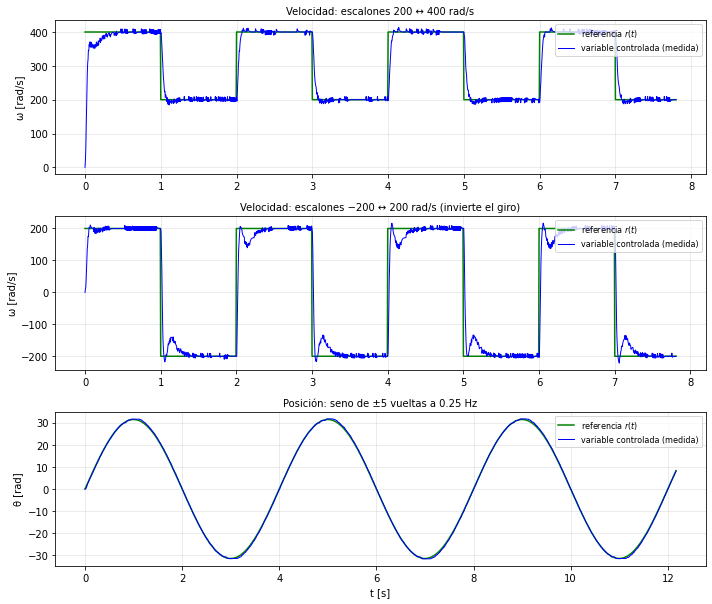

,sobreimpulso_pct,t_establecimiento_s,error_final,error_rms
prueba,,,,
velocidad_cuadrada_200_400,6.48429,0.188571,0.1907,35.0838
velocidad_cuadrada_menos200_200,3.69143,0.259286,0.129443,53.0972
posicion_seno_5vueltas,NaN,NaN,NaN,0.3322


In [24]:
# =============================================================================
#  PID REAL: seguimiento de la referencia (mediciones del Arduino)
#  Columnas de los CSV: t_s, k, cuenta, theta_rad, referencia, omega_rad_s, voltaje_V, ...
# =============================================================================
import json
CARPETA_PID = Path("ParteExperimental/datos/tema4_20261122/c_pid")
casos_pid = [("velocidad_cuadrada_200_400", "vel", "Velocidad: escalones 200 ↔ 400 rad/s"),
             ("velocidad_cuadrada_menos200_200", "vel", "Velocidad: escalones −200 ↔ 200 rad/s (invierte el giro)"),
             ("posicion_seno_5vueltas", "pos", "Posición: seno de ±5 vueltas a 0.25 Hz")]
fig, ejes = plt.subplots(len(casos_pid), 1, figsize=(10, 8.5))
filas_pid = []
for ax, (nombre, modo, titulo) in zip(ejes, casos_pid):
    x = np.loadtxt(CARPETA_PID / f"{nombre}.csv", delimiter=",", skiprows=1)
    t, ref = x[:, 0], x[:, 4]
    y = x[:, 5] if modo == "vel" else x[:, 3]
    ax.plot(t, ref, "g-", lw=1.5, label="referencia $r(t)$")
    ax.plot(t, y, "b-", lw=1.0, label="variable controlada (medida)")
    ax.set_ylabel("ω [rad/s]" if modo == "vel" else "θ [rad]"); ax.set_title(titulo, fontsize=10)
    ax.legend(loc="upper right", fontsize=8)
    m = json.load(open(CARPETA_PID / f"{nombre}.json", encoding="utf-8"))
    e = m["escalones"]
    filas_pid.append(dict(prueba=nombre,
                          sobreimpulso_pct=np.mean([q["sobreimpulso_%"] for q in e]) if e else np.nan,
                          t_establecimiento_s=np.nanmean([q["t_establecimiento_5%_s"] for q in e]) if e else np.nan,
                          error_final=np.mean([abs(q["error_final_medio"]) for q in e]) if e else np.nan,
                          error_rms=m["resumen"]["error_rms"]))
ejes[-1].set_xlabel("t [s]"); plt.tight_layout(); plt.show()
display(pd.DataFrame(filas_pid).set_index("prueba"))

### *5.2.1. Diagrama de bloques del lazo cerrado*

El controlador trabaja en tiempo discreto y la planta en tiempo continuo. Los interruptores marcan dónde se muestrea con periodo $T_s$; el retenedor mantiene el voltaje constante durante cada periodo (PWM del L298N).

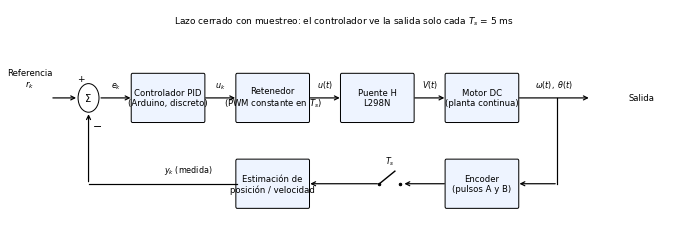

In [25]:
# =============================================================================
#  Diagrama de bloques del lazo cerrado con muestreo (sin notación de Laplace)
# =============================================================================
from matplotlib.patches import FancyBboxPatch

def bloque(ax, x, y, texto, w=1.7, h=0.8):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.03", fc="#eef4ff", ec="k"))
    ax.text(x, y, texto, ha="center", va="center", fontsize=8.5)

def flecha(ax, x0, y0, x1, y1, texto=None, dy=0.18):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="->", lw=1.2))
    if texto: ax.text((x0 + x1) / 2, (y0 + y1) / 2 + dy, texto, ha="center", fontsize=8)

def interruptor(ax, x, y, etiqueta="$T_s$"):
    ax.plot([x - 0.25, x + 0.12], [y, y + 0.22], "k-", lw=1.4); ax.plot([x - 0.25, x + 0.25], [y, y], "k.", ms=5)
    ax.text(x, y + 0.35, etiqueta, ha="center", fontsize=8)

fig, ax = plt.subplots(figsize=(12, 4)); ax.set_xlim(-0.5, 15.5); ax.set_ylim(-2.2, 1.6); ax.axis("off")
ax.text(0.0, 0.2, "Referencia\n$r_k$", ha="center", fontsize=8.5)
ax.add_patch(plt.Circle((1.4, 0), 0.25, fc="w", ec="k")); ax.text(1.4, 0, "Σ", ha="center", va="center")
ax.text(1.12, 0.3, "+", fontsize=9); ax.text(1.5, -0.55, "−", fontsize=11)
flecha(ax, 0.5, 0, 1.15, 0)
bloque(ax, 3.3, 0, "Controlador PID\n(Arduino, discreto)")
flecha(ax, 1.65, 0, 2.45, 0, "$e_k$")
bloque(ax, 5.8, 0, "Retenedor\n(PWM constante en $T_s$)")
flecha(ax, 4.15, 0, 4.95, 0, "$u_k$")
bloque(ax, 8.3, 0, "Puente H\nL298N")
flecha(ax, 6.65, 0, 7.45, 0, "$u(t)$")
bloque(ax, 10.8, 0, "Motor DC\n(planta continua)")
flecha(ax, 9.15, 0, 9.95, 0, "$V(t)$")
flecha(ax, 11.65, 0, 13.4, 0, "$\\omega(t),\\ \\theta(t)$")
ax.text(14.3, 0, "Salida", va="center", fontsize=8.5)
bloque(ax, 10.8, -1.5, "Encoder\n(pulsos A y B)")
ax.plot([12.6, 12.6], [0, -1.5], "k-", lw=1.2); flecha(ax, 12.6, -1.5, 11.65, -1.5)
interruptor(ax, 8.6, -1.5)
bloque(ax, 5.8, -1.5, "Estimación de\nposición / velocidad")
flecha(ax, 9.95, -1.5, 8.9, -1.5); flecha(ax, 8.35, -1.5, 6.65, -1.5)
ax.plot([4.95, 1.4], [-1.5, -1.5], "k-", lw=1.2); flecha(ax, 1.4, -1.5, 1.4, -0.25)
ax.text(3.2, -1.3, "$y_k$ (medida)", fontsize=8)
ax.text(7.5, 1.3, "Lazo cerrado con muestreo: el controlador ve la salida solo cada $T_s$ = 5 ms", ha="center", fontsize=9)
plt.show()

# ***PREGUNTAS OBLIGATORIAS***


**1. ¿Qué paso máximo permite Euler explícito antes de volverse inestable y cómo se relaciona con $L/R$?**

Para el sistema $\mathbf{y}'=\mathbf{f}(\mathbf{y})$, Euler es estable si $|1+h\lambda|<1$ para todos los valores propios del Jacobiano, es decir, $h < -2\,\mathrm{Re}(\lambda)/|\lambda|^2$. El valor propio más rápido es el eléctrico, $\lambda_e\approx -R/L$, así que el paso máximo es $h_{max}\approx 2L/R = 2\tau_e$, el doble de la constante de tiempo eléctrica. Con $L=2$ mH y $R=2\ \Omega$ se calculó $h_{max}=2.14$ ms con los valores propios completos y se observó **2.16 ms** al simular. Despreciando $L$ el límite sube a ≈ 30 ms. (Sección 4.3.)

**2. ¿Cuánto cambia el desempeño del PID real si el término derivativo usa diferencias hacia atrás crudas en lugar de una derivada filtrada?**

El sobreimpulso baja de ≈ 15 % (filtrada, $\tau_f=20$ ms) a ≈ 8 % (cruda), porque la cruda no tiene retraso. A cambio, el voltaje tiembla ≈ 0.44 V con el eje quieto, contra ≈ 0 V del filtro, porque el ruido de cuantización del encoder pasa directo al actuador. La derivada con ventana corta ($k=5$) queda en un punto intermedio y fue la mejor en esta prueba (≈ 6.5 % de sobreimpulso y ≈ 0.15 V de temblor). Es el compromiso de la sección 2.5: menos ruido cuesta retraso. (Sección 5.1.)

**3. ¿Qué parámetro del modelo explica la mayor discrepancia entre el gemelo digital y el motor real a bajas velocidades? ¿Qué fracción de la energía eléctrica se convierte en trabajo mecánico útil?**

*Parámetro.* A bajas velocidades manda la fricción de Coulomb: es mayor que la viscosa mientras $\omega<\tau_c/b\approx 49$ rad/s, y perturbar $\tau_c$ ±20 % cambia el tiempo de parada 12 a 17 %, contra 5 a 6 % con $b$. (Sección 4.2.) Con el motor real habrá que comprobar si se mantiene, porque $\tau_c$ también absorbe cualquier error en el modelo de fricción cerca de $\omega=0$.

*Energía.* De la energía eléctrica, entre ≈ 80 y 86 % se convierte en energía mecánica ($\eta_{conv}$), pero **sin carga externa casi toda se disipa en fricción**; lo que queda como energía mecánica útil almacenada es la cinética: ≈ 3 a 5 % sin carga y ≈ 5 a 9 % con el disco en escalones de 1.6 s. Con $\tau_{carga}\neq 0$ habría trabajo útil adicional $\int\tau_{carga}\,\omega\,dt$, que en estas pruebas no se midió. (Secciones 3.7 y 3.8.)

# ***CONCLUSIONES***

> *Borrador redactado con ayuda de IA a partir de los resultados de este cuaderno (ver la bitácora). El equipo debe revisarlo y ajustarlo a su análisis.*

1. **Modelo.** El sistema eléctrico-mecánico del motor es rígido: con los parámetros estimados de las mediciones, los valores propios del Jacobiano están separados por más de un orden de magnitud, por la diferencia entre la constante de tiempo eléctrica ($L/R$, de milisegundos) y la mecánica (décimas de segundo).
2. **Métodos para EDO.** Euler explícito solo es estable si $h$ es menor que un paso crítico del orden de $2L/R$; por encima de ese valor la solución oscila y diverge (secciones 4.3 y 4.4). Heun, RK2 y RK4 permiten pasos mayores para la misma precisión, y RK4 alcanza el orden 4 observado en el estudio de convergencia.
3. **Derivación.** Con un encoder de 44 cuentas por vuelta, la derivada con paso pequeño está dominada por la cuantización (un pulso en 0,5 ms equivale a cientos de rad/s). Aumentar la ventana reduce el ruido, pero agrega retraso. Richardson con ventanas grandes da la mejor estimación en régimen, y la ventana debe elegirse según qué se necesite: el transitorio o el valor estacionario.
4. **Integración.** El trapecio, Simpson y Gauss-Legendre dan energías que coinciden dentro de una fracción de porcentaje. La diferencia entre métodos es mucho menor que la incertidumbre de las mediciones (el voltaje es el *pedido*, no el medido en los bornes).
5. **Gemelo digital.** El modelo reproduce la forma de las respuestas, pero con errores del orden de 20 % en $\omega$. La causa principal identificada es que el voltaje medio en el motor no es proporcional al PWM con el L298N a 490 Hz; la fricción de Coulomb domina a bajas velocidades.
6. **Carga.** El cilindro de PVC casi no cambia la respuesta, porque está en el eje de salida, detrás de una caja de reducción grande: su inercia vista desde el motor se divide entre $N^2$.
7. **Control PID.** Implementado en el Arduino con $T_s = 5$ ms, el PI de velocidad sigue escalones con 4–7 % de sobreimpulso y error estacionario menor a 0,5 rad/s, y el PID de posición sigue una senoidal de ±5 vueltas con un error RMS de 0,33 rad. A bajas velocidades el desempeño empeora por la cuantización del encoder y la fricción.

# ***REFERENCIAS***

[1] N. S. Nise, *Control Systems Engineering*, 7th ed. Hoboken, NJ, USA: John Wiley & Sons, 2015.